# 2.08. Регрессионные модели

**План занятия**

1. Потенциальные исходы, смещение и зачем нужна рандомизация.
2. Линейная регрессия как инструмент причинного анализа.
3. Смещение из-за пропущенных переменных.
4. Какие переменные включать в модель, а какие нельзя.
5. Инструментальные переменные и слабые инструменты.
6. Несоблюдение назначения и LATE.
7. Разрывная регрессия: резкая и нечёткая.

### Библиотеки

Кроме стандартного набора нужны `linearmodels` и `rdrobust`. В Colab их можно поставить командой `!pip install -q linearmodels rdrobust`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from ipywidgets import FloatSlider, IntSlider, interact
from linearmodels.iv import IV2SLS
from rdrobust import rdrobust
from scipy.special import expit

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
DATA = 'data/'
rng = np.random.default_rng(42)


def draw_dag(ax, edges, pos, title='', fixed=()):
    """Рисует граф: edges — пары (откуда, куда) или тройки с цветом стрелки, fixed — зафиксированные вершины."""
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
    for edge in edges:
        ax.annotate('', xy=pos[edge[1]], xytext=pos[edge[0]],
                    arrowprops=dict(arrowstyle='-|>', lw=1.8, mutation_scale=14, shrinkA=24, shrinkB=24,
                                    color=edge[2] if len(edge) == 3 else GRAY))
    for name, (x, y) in pos.items():
        ax.text(x, y, name, ha='center', va='center', fontsize=11,
                bbox=dict(boxstyle='round,pad=0.4', fc='#EEEEEE' if name in fixed else 'white', ec=GRAY))
    xs, ys = zip(*pos.values())
    ax.set_xlim(min(xs) - 0.35, max(xs) + 0.35)
    ax.set_ylim(min(ys) - 0.25, max(ys) + 0.25)


def coef_row(model, term, label):
    """Собирает оценку коэффициента в строку таблицы."""
    low, high = model.conf_int().loc[term]
    return {'Модель': label, 'Оценка': model.params[term], 'SE': model.bse[term],
            'ДИ 2.5%': low, 'ДИ 97.5%': high, 'p-value': model.pvalues[term]}


def plot_forest(ax, table, xlabel, truth=None):
    """Показывает оценки и 95% интервалы из таблицы coef_row."""
    y = np.arange(len(table))[::-1]
    ax.errorbar(table['Оценка'], y, xerr=[table['Оценка'] - table['ДИ 2.5%'], table['ДИ 97.5%'] - table['Оценка']],
                fmt='o', color=BLUE, capsize=4, lw=1.8)
    ax.axvline(0, color=GRAY, lw=1)
    if truth is not None:
        ax.axvline(truth, color=GREEN, ls='--', label='Истинный эффект')
        ax.legend()
    ax.set_yticks(y, table['Модель'])
    ax.set_ylim(-0.6, len(table) - 0.4)
    ax.set_xlabel(xlabel)

## Причинно-следственный анализ

Модели машинного обучения хорошо решают задачи прогноза: переводят тексты и распознают лица. Но на вопросы «что, если» (контрфактические вопросы) они сами по себе не отвечают. Для этого нужен **каузальный вывод**. Это не новая область: экономисты, биостатистики и психологи десятилетиями оценивают влияние образования на доходы или насыщенных жиров на сердечные приступы.

Основное правило знакомо многим: **[«корреляция не означает причинность»](https://en.wikipedia.org/wiki/Correlation_does_not_imply_causation)**. Из того, что две переменные движутся вместе, нельзя сделать вывод, что одна вызывает другую. Эта ошибка называется **cum hoc ergo propter hoc** («вместе с этим, значит из-за этого»). Причин у такой корреляции три.

* **Обратная причинность (Reverse Causation).** Кажется, что А вызывает В, а на самом деле В вызывает А. Ветряные мельницы вращаются быстрее при сильном ветре, но ветер создают не они. Низкий холестерин связан с повышенной смертностью, но часто потому, что тяжёлая болезнь, например рак, сама снижает холестерин.

* **Общий фактор (Confounder).** Корреляция возникает из-за третьей переменной, которая влияет и на А, и на В.
    * Школы с планшетами показывают лучшие результаты. Возможно, богатые школы могут позволить себе и планшеты, и сильных учителей.
    * Люди, уснувшие в обуви, часто просыпаются с головной болью. Вероятная общая причина — алкоголь перед сном.
    * Продажи мороженого коррелируют с числом утоплений. Общий фактор — летняя жара.
    * Исторический пример: европейцы в Средние века считали, что вши полезны для здоровья, потому что они покидали больного до появления симптомов. На самом деле вшей прогоняло небольшое повышение температуры, а заметные симптомы появлялись позже.

* **Случайное совпадение (Coincidental Relationship).** Чем больше данных мы просматриваем, тем выше шанс найти случайную корреляцию. Результат последней домашней игры вашингтонской футбольной команды (сейчас Commanders) перед президентскими выборами в США совпадал с исходом выборов с 1936 по 2000 год, хотя матчи на выборы не влияют.

В основе подхода лежит **фреймворк потенциальных исходов (Potential Outcomes Framework)**, или **модель Рубина (Rubin Causal Model)**. Для каждой единицы $i$ рассматриваются два потенциальных исхода: $Y_{1i}$ — исход при воздействии и $Y_{0i}$ — исход той же единицы без воздействия. Наблюдаемый исход равен

$$Y_i = Y_{1i} T_i + Y_{0i} (1 - T_i),$$

где $T_i$ — флаг воздействия.

**Фундаментальная проблема каузального вывода** состоит в том, что мы никогда не видим оба исхода одной единицы. Индивидуальный эффект $\tau_i = Y_{1i} - Y_{0i}$ измерить нельзя, поэтому оценивают средние эффекты:

* **ATE (Average Treatment Effect)** — $E[Y_1 - Y_0]$.
* **ATT (Average Treatment effect on the Treated)** — $E[Y_1 - Y_0 \mid T = 1]$.
* **ATU (Average Treatment effect on the Untreated)** — $E[Y_1 - Y_0 \mid T = 0]$.
* **CATE (Conditional Average Treatment Effect)** — $E[Y_1 - Y_0 \mid X = x]$.
* **LATE (Local Average Treatment Effect)** — $E[Y_1 - Y_0 \mid \text{Compliers}]$.

Разницу между простой ассоциацией и причинным эффектом объясняет **смещение (bias)**:

$$
E[Y|T=1] - E[Y|T=0] = E[Y_1|T=1] - E[Y_0|T=0] + E[Y_0|T=1] - E[Y_0|T=1] = \underbrace{E[Y_1 - Y_0|T=1]}_{ATT} + \underbrace{E[Y_0|T=1] - E[Y_0|T=0]}_{BIAS}
$$

Смещение показывает, насколько группы различались бы, если бы **никто из них не получил воздействия**. Если школы с планшетами были бы лучше и без планшетов, то $E[Y_0|T=1] > E[Y_0|T=0]$, и наблюдаемая разница завышена.

**Задача каузального вывода** — устранить это смещение. Если оно равно нулю, ассоциация равна ATT. Чтобы она равнялась ещё и ATE, эффект в группах в среднем тоже должен совпадать.

**A/B-тест** решает обе проблемы одним ходом. При случайном назначении потенциальные исходы не зависят от $T$: $(Y_0, Y_1) \perp T$. Поэтому группы сопоставимы до начала воздействия, смещение исчезает, а ATT равен ATE. Простая разница средних становится несмещённой оценкой ATE.

Проверим разложение на симуляции. В ней мы, в отличие от реальности, знаем оба потенциальных исхода.

In [2]:
n = 200_000
wealth = rng.normal(0, 1, n)
y0 = 60 + 5 * wealth + rng.normal(0, 5, n)
y1 = y0 + 2 + wealth

t_observed = rng.random(n) < expit(2 * wealth)  # планшеты чаще у богатых школ
t_random = rng.random(n) < 0.5

rows = []
for name, t in [('Наблюдательные данные', t_observed), ('Рандомизация', t_random)]:
    y = np.where(t, y1, y0)
    rows.append({'Схема': name,
                 'Разница средних': y[t].mean() - y[~t].mean(),
                 'ATT': (y1 - y0)[t].mean(),
                 'BIAS': y0[t].mean() - y0[~t].mean(),
                 'ATE': (y1 - y0).mean()})
pd.DataFrame(rows).round(3)

,Схема,Разница средних,ATT,BIAS,ATE
0,Наблюдательные данные,8.681,2.607,6.074,1.999
1,Рандомизация,1.974,1.997,-0.023,1.999


В наблюдательных данных разница средних 8.68 равна сумме ATT 2.61 и смещения 6.07. ATT здесь отличается и от ATE, потому что эффект сильнее у богатых школ. После рандомизации смещение равно нулю с точностью до шума, а ATT совпадает с ATE.

У A/B-тестов есть ограничения, и здесь помогают методы каузального вывода для **наблюдательных данных**.

1. **Рандомизация невозможна.** Иногда её нельзя провести практически или этически: нельзя случайным образом заставить людей курить, чтобы изучить влияние на рак лёгких.
2. **Есть смешивающие факторы (confounders).** Без рандомизации на воздействие и исход часто влияет что-то общее. Если такой фактор наблюдаем, его можно учесть в регрессии. Если нет, нужны другие стратегии.

Каждому случаю соответствует свой метод этой лекции:

* регрессия работает, если все конфаундеры измерены;
* инструментальная переменная работает, если есть случайная причина воздействия, которая влияет на исход только через него;
* разрывная регрессия работает, если воздействие зависит от порога по наблюдаемой переменной.

Ни один из этих методов не превращает ассоциацию в причинность автоматически. Каждый опирается на предположения, которые нужно обосновать, и часть из них нельзя проверить на данных.

## Линейная регрессия

Индивидуальный эффект $\tau_i = Y_{1i} - Y_{0i}$ неизвестен, поэтому сосредоточимся на среднем эффекте $ATE = E[Y_1 - Y_0]$.

Начнём с упрощённой модели с постоянным эффектом: $Y_{1i} = Y_{0i} + \kappa$. Если $\kappa$ положительно, воздействие помогает всем одинаково. Это сильное упрощение. Если эффект неоднороден, регрессия оценивает его средневзвешенное значение. Веса зависят от модели, и к этому мы ещё вернёмся.

Мы уже знаем, что разницу средних нельзя считать эффектом из-за смещения. A/B-тест, или **рандомизированное контролируемое испытание** (РКИ), его устраняет. Посмотрим, как сделать то же самое с помощью рабочей лошадки причинного анализа — **линейной регрессии**.

В данных эксперимента студентов случайно распределили между форматами занятий, и мы сравним онлайн с очным:

$$
exam_i = \beta_0 + \kappa \ Online_i + u_i
$$

Здесь $\beta_0$ — базовый результат, а $\kappa$ — добавка за онлайн. На оценку влияет многое другое, и всё это попадает в ошибку модели $u_i$.

Переменная $Online$ — бинарный флаг воздействия. Регрессия восстановит $E[Y|T=0] = \beta_0$ и $E[Y|T=1] = \beta_0 + \kappa$. Причинным эффектом $\kappa$ становится не из-за регрессии, а из-за рандомизации формата.

In [3]:
exam = pd.read_csv(DATA + 'regression_df_one.csv').query('format_blended == 0')

result = smf.ols('falsexam ~ format_ol', data=exam).fit()
print(result.summary().tables[1])
print('Среднее очно: ', round(exam.query('format_ol == 0')['falsexam'].mean(), 4))
print('Среднее онлайн:', round(exam.query('format_ol == 1')['falsexam'].mean(), 4))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     78.5475      1.113     70.563      0.000      76.353      80.742
format_ol     -4.9122      1.680     -2.925      0.004      -8.223      -1.601
Среднее очно:  78.5475
Среднее онлайн: 73.6353


Регрессия сравнивает именно то, что нужно. Свободный член равен среднему при очном формате, а коэффициент — разнице средних: $78.55 - 4.91 = 73.64$, это среднее в онлайн-группе. При этом мы бесплатно получаем доверительный интервал и p-value.

### Теория регрессии

Регрессия решает задачу наилучшего линейного прогноза:

$$
\beta^* = \underset{\beta}{argmin} \ E[(Y_i - X_i'\beta)^2]
$$

где $X_i$ — вектор-столбец признаков объекта $i$. Если продифференцировать и приравнять к нулю, получим

$$
\beta^* = E[X_i X_i']^{-1} E[X_i Y_i]
$$

Выборочный аналог этой формулы, где $X$ — матрица объектов-признаков:

$$
\hat{\beta} = (X'X)^{-1}X' Y
$$

In [4]:
X = exam[['format_ol']].assign(intercept=1)
y = exam['falsexam']


def regress(y, X):
    return np.linalg.solve(X.T.dot(X), X.T.dot(y))


beta = regress(y, X)
beta

array([-4.9122215 , 78.54748458])

Для одного регрессора $T$ формула упрощается:

$$
\kappa = \dfrac{Cov(Y_i, T_i)}{Var(T_i)}
$$

Если $T$ назначено случайно, это ATE.

Если регрессоров несколько, то есть

$$
y_i = \beta_0 + \kappa T_i + \beta_1 X_{1i} + ... +\beta_k X_{ki} + u_i,
$$

а нас интересует только $\kappa$, работает **теорема Фриша — Во — Ловелла**:

$$
\kappa = \dfrac{Cov(Y_i, \tilde{T_i})}{Var(\tilde{T_i})}
$$

где $\tilde{T_i}$ — остаток регрессии $T_i$ на все остальные ковариаты.

Смысл такой. Если $T$ можно предсказать по другим переменным, оно неслучайно. Но остаток $\tilde{T}$ уже нельзя предсказать по этим $X$. Регрессия использует только ту часть вариации воздействия, которая с ними не связана. Это устраняет смещение только от учтённых переменных: про неизмеренные факторы остаток ничего не знает.

Это опирается на свойство МНК: остатки ортогональны всем переменным модели.

In [5]:
e = y - X.dot(beta)
print('Скалярные произведения остатков с регрессорами:', np.dot(e, X).round(9))
print('Корреляция остатков с воздействием:', round(np.corrcoef(e, X['format_ol'])[0, 1], 9))

Скалярные произведения остатков с регрессорами: [-0.  0.]
Корреляция остатков с воздействием: -0.0


### Регрессия на неслучайных данных

Эксперименты дороги, а иногда невозможны. Очень сложно убедить McKinsey & Co. работать бесплатно ради того, чтобы отделить ценность их услуг от того, что их клиенты и так состоятельны.

Перейдём к наблюдательным данным и оценим влияние дополнительного года обучения на зарплату. Рандомизировать людей на 4, 8 или 12 лет обучения нельзя. Начнём с простой модели для логарифма почасовой оплаты. Логарифм даёт коэффициентам процентную интерпретацию ([почему так](https://stats.stackexchange.com/questions/244199/why-is-it-that-natural-log-changes-are-percentage-changes-what-is-about-logs-th)):

$$
log(hwage)_i = \beta_0 + \beta_1 educ_i + u_i
$$

Данные похожи на набор WAGE2 из учебника Вулдриджа: только мужчины 28–38 лет, `wage` — месячный заработок, `hours` — среднее число часов в неделю. Столбец `lhwage` равен $\log(wage / hours)$, то есть это ещё не настоящая почасовая оплата: не хватает числа недель в месяце. На коэффициенты это не влияет, потому что меняется только свободный член. На графике ниже мы делим ещё на $52/12$.

In [6]:
wage_raw = pd.read_csv(DATA + 'regression_df_two.csv')
wage = wage_raw.dropna()
print(f'Строк: {len(wage_raw)}, полных строк: {len(wage)}')

model_1 = smf.ols('lhwage ~ educ', data=wage).fit()
print(model_1.summary().tables[1])

Строк: 935, полных строк: 663
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.3071      0.104     22.089      0.000       2.102       2.512
educ           0.0536      0.008      7.114      0.000       0.039       0.068


Оценка $\beta_1$ равна 0.0536 с 95% интервалом (0.039, 0.068). Модель **предсказывает** рост зарплаты примерно на $e^{0.0536} - 1 = 5.5\%$ за год обучения. Рост в процентах означает экспоненциальную зависимость: чем выше база, тем больше прибавка в деньгах.

Отметим, что для анализа мы выкинули 272 строки с пропусками в образовании родителей и порядке рождения. Это удобно, но выборка уже не совсем та.

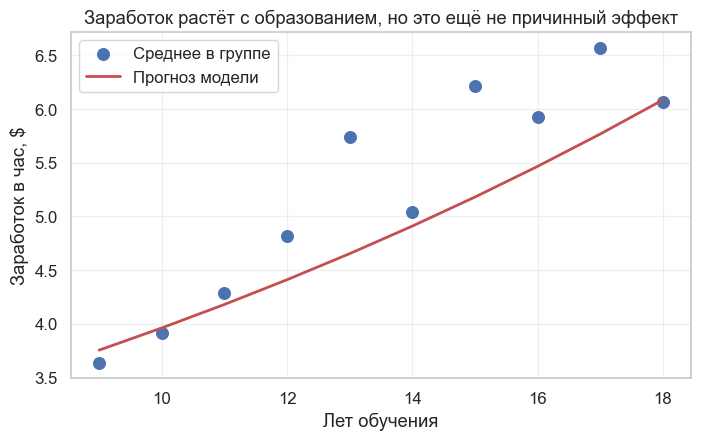

In [7]:
HOURS_FACTOR = 52 / 12
x = np.arange(9, 19)
by_educ = wage.assign(hourly=wage['wage'] / wage['hours'] / HOURS_FACTOR).groupby('educ')['hourly'].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(by_educ.index, by_educ, s=70, color=BLUE, label='Среднее в группе')
ax.plot(x, np.exp(model_1.params['Intercept'] + model_1.params['educ'] * x) / HOURS_FACTOR, color=RED, lw=2, label='Прогноз модели')
ax.set_xlabel('Лет обучения')
ax.set_ylabel('Заработок в час, $')
ax.set_title('Заработок растёт с образованием, но это ещё не причинный эффект')
ax.legend();

Мы осторожно сказали, что модель **предсказывает**, а не вызывает рост. То, что модель можно оценить, не делает её причинной. Данные не получены в эксперименте, поэтому люди с разным образованием могут быть несопоставимы. У получивших больше образования, вероятно, более богатые родители, и часть роста зарплаты отражает благосостояние семьи: $E[Y_0|T=0] < E[Y_0|T=1]$. Можно даже утверждать, что образование снижает зарплату, потому что люди дольше не работают и теряют опыт.

К счастью, в данных есть другие переменные: образование родителей (`meduc`, `feduc`), показатель IQ, опыт (`exper`), стаж в текущей компании (`tenure`), флаги брака и этнической принадлежности.

In [8]:
wage.head()

,wage,hours,lhwage,IQ,educ,exper,tenure,age,married,black,south,urban,sibs,brthord,meduc,feduc
0,769,40,2.956212,93,12,11,2,31,1,0,0,1,1,2.0,8.0,8.0
2,825,40,3.026504,108,14,11,9,33,1,0,0,1,1,2.0,14.0,14.0
3,650,40,2.788093,96,12,13,7,32,1,0,0,1,4,3.0,12.0,12.0
4,562,40,2.642622,74,11,14,5,34,1,0,0,1,10,6.0,6.0,11.0
6,600,40,2.708050,91,10,13,0,30,0,0,0,1,1,2.0,8.0,8.0


Включим их в модель:

$$
log(hwage)_i = \beta_0 + \kappa \ educ_i + \pmb{\beta}X_i + u_i
$$

Вспомним формулу с остатками:

$$
\kappa = \dfrac{Cov(Y_i, \tilde{T_i})}{Var(\tilde{T_i})}
$$

Мы предсказываем `educ` по контролям и оставляем часть $\tilde{educ}$, которая с ними не коррелирует. Это снимает возражение «образование лишь коррелирует с IQ, а зарплату определяет IQ»: если IQ в модели, $\kappa$ сравнивает людей с одинаковым IQ. Там, где нет РКИ, регрессия удерживает факторы на одном уровне, но только измеренные.

In [9]:
controls = ['IQ', 'exper', 'tenure', 'age', 'married', 'black',
            'south', 'urban', 'sibs', 'brthord', 'meduc', 'feduc']

X = wage[controls].assign(intercept=1)
t = wage['educ']
y = wage['lhwage']

beta_aux = regress(t, X)
t_tilde = t - X.dot(beta_aux)

kappa = t_tilde.cov(y) / t_tilde.var()
kappa

np.float64(0.04114719101006261)

При одинаковых значениях контролей дополнительный год обучения связан с ростом оплаты примерно на 4.1%. Оценка снизилась по сравнению с 5.4%, что похоже на положительное смещение в простой модели. Но вывод об эффекте делать рано: среди этих контролей есть переменные, которые нельзя было включать. Мы вернёмся к этому в разделе про плохие контроли.

Та же оценка с интервалом получается из готовой реализации.

In [10]:
model_2 = smf.ols('lhwage ~ educ + ' + ' + '.join(controls), data=wage).fit()
print(model_2.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1156      0.232      4.802      0.000       0.659       1.572
educ           0.0411      0.010      4.075      0.000       0.021       0.061
IQ             0.0038      0.001      2.794      0.005       0.001       0.006
exper          0.0153      0.005      3.032      0.003       0.005       0.025
tenure         0.0094      0.003      2.836      0.005       0.003       0.016
age            0.0086      0.006      1.364      0.173      -0.004       0.021
married        0.1795      0.053      3.415      0.001       0.076       0.283
black         -0.0801      0.063     -1.263      0.207      -0.205       0.044
south         -0.0397      0.035     -1.129      0.259      -0.109       0.029
urban          0.1926      0.036      5.418      0.000       0.123       0.262
sibs           0.0065      0.009      0.722      0.4

## Смещение из-за пропущенных переменных (Omitted Variable Bias)

Является ли оценка причинной? Сказать наверняка нельзя. Простая модель, скорее всего, нет: она не учитывает переменные, связанные и с образованием, и с зарплатой.

Пусть истинная модель выглядит так:

$$
Wage_i = \alpha + \kappa \ Educ_i + A_i'\beta + u_i
$$

Здесь $A$ — вектор способностей. Если выбросить его из модели, то оценка будет равна

$$
\dfrac{Cov(Wage_i, Educ_i)}{Var(Educ_i)} = \kappa + \beta'\delta_{A}
$$

где $\delta_{A}$ — вектор коэффициентов регрессии $A$ на $Educ$.

Смещение $\beta'\delta_{A}$ — это влияние пропущенной переменной на исход, умноженное на её связь с воздействием. Отсюда два вывода:

* смещения нет, если пропущенная переменная не влияет на исход;
* смещения нет, если она не связана с воздействием.

Смещение возникает, только если переменная влияет на исход и связана с воздействием. Такую переменную называют **конфаундером**: она определяет и воздействие, и исход. В примере с зарплатой это IQ: люди с высоким IQ обычно учатся дольше и, как правило, зарабатывают больше.

Формула здесь не приближённая, а точное тождество МНК. Проверим его для IQ.

In [11]:
short = smf.ols('lhwage ~ educ', data=wage).fit()
long = smf.ols('lhwage ~ educ + IQ', data=wage).fit()
delta = smf.ols('IQ ~ educ', data=wage).fit().params['educ']

print(f"Короткая модель:              {short.params['educ']:.6f}")
print(f"Длинная модель:               {long.params['educ']:.6f}")
print(f"beta_IQ * delta:              {long.params['IQ'] * delta:.6f}")
print(f"Длинная + beta_IQ * delta:    {long.params['educ'] + long.params['IQ'] * delta:.6f}")

Короткая модель:              0.053605
Длинная модель:               0.034864
beta_IQ * delta:              0.018741
Длинная + beta_IQ * delta:    0.053605


На графах стрелками показаны причинные связи, красным — положительные, синим — отрицательные.

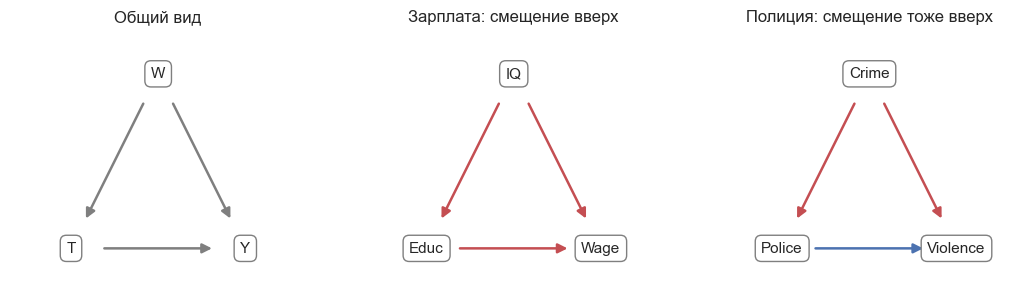

In [12]:
triangle = {'W': (0.5, 1), 'T': (0, 0), 'Y': (1, 0)}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
draw_dag(axes[0], [('W', 'T'), ('W', 'Y'), ('T', 'Y')], triangle, 'Общий вид')
draw_dag(axes[1], [('IQ', 'Educ', RED), ('IQ', 'Wage', RED), ('Educ', 'Wage', RED)],
         {'IQ': (0.5, 1), 'Educ': (0, 0), 'Wage': (1, 0)}, 'Зарплата: смещение вверх')
draw_dag(axes[2], [('Crime', 'Police', RED), ('Crime', 'Violence', RED), ('Police', 'Violence', BLUE)],
         {'Crime': (0.5, 1), 'Police': (0, 0), 'Violence': (1, 0)}, 'Полиция: смещение тоже вверх');

Знак смещения равен произведению знаков двух стрелок, идущих из конфаундера.

В примере с зарплатой обе стрелки положительны, поэтому без IQ эффект образования кажется выше, чем есть. Это положительное смещение.

В примере с полицией в городах с большим числом полицейских больше насилия. Возможно, полиция на самом деле снижает насилие, а преступность увеличивает и насилие, и штат полиции. Обе стрелки из `Crime` положительны, поэтому смещение тоже **положительное**: отрицательный эффект выглядит менее отрицательным или даже положительным. Отрицательное смещение было бы, если бы стрелки из конфаундера имели разные знаки.

Подвигайте ползунки: они задают влияние скрытой переменной $U$ на $T$ и $Y$ и настоящий эффект.

In [13]:
def plot_ovb(ax, u_to_t, u_to_y, kappa, n=3000, seed=1):
    """Сравнивает наивную оценку с оценкой при контроле конфаундера U."""
    local = np.random.default_rng(seed)
    u = local.normal(0, 1, n)
    t = u_to_t * u + local.normal(0, 1, n)
    y = kappa * t + u_to_y * u + local.normal(0, 1, n)
    data = pd.DataFrame({'y': y, 't': t, 'u': u})
    naive = smf.ols('y ~ t', data).fit().params['t']
    adjusted = smf.ols('y ~ t + u', data).fit().params['t']
    formula = u_to_y * u_to_t / (u_to_t ** 2 + 1)

    ax.scatter(t, y, s=6, c=u, cmap='coolwarm', alpha=0.5)
    grid = np.array([t.min(), t.max()])
    ax.plot(grid, y.mean() + naive * (grid - t.mean()), color='black', lw=2.5, label=f'Наивная: {naive:.2f}')
    ax.plot(grid, y.mean() + adjusted * (grid - t.mean()), color=GREEN, lw=2.5, label=f'С контролем U: {adjusted:.2f}')
    ax.set_title(f'Смещение по формуле: {formula:+.2f}', fontsize=12)
    ax.set_xlabel('T')
    ax.set_ylabel('Y')
    ax.legend(fontsize=10)


def ovb_demo(u_to_t=1.0, u_to_y=1.0, kappa=-0.5):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    plot_ovb(ax, u_to_t, u_to_y, kappa)
    plt.show()


interact(ovb_demo,
         u_to_t=FloatSlider(value=1, min=-2, max=2, step=0.25, description='U→T'),
         u_to_y=FloatSlider(value=1, min=-2, max=2, step=0.25, description='U→Y'),
         kappa=FloatSlider(value=-0.5, min=-2, max=2, step=0.25, description='Эффект'));

Статичная версия для четырёх комбинаций знаков. Цвет точек показывает значение $U$, настоящий эффект везде равен $-0.5$.

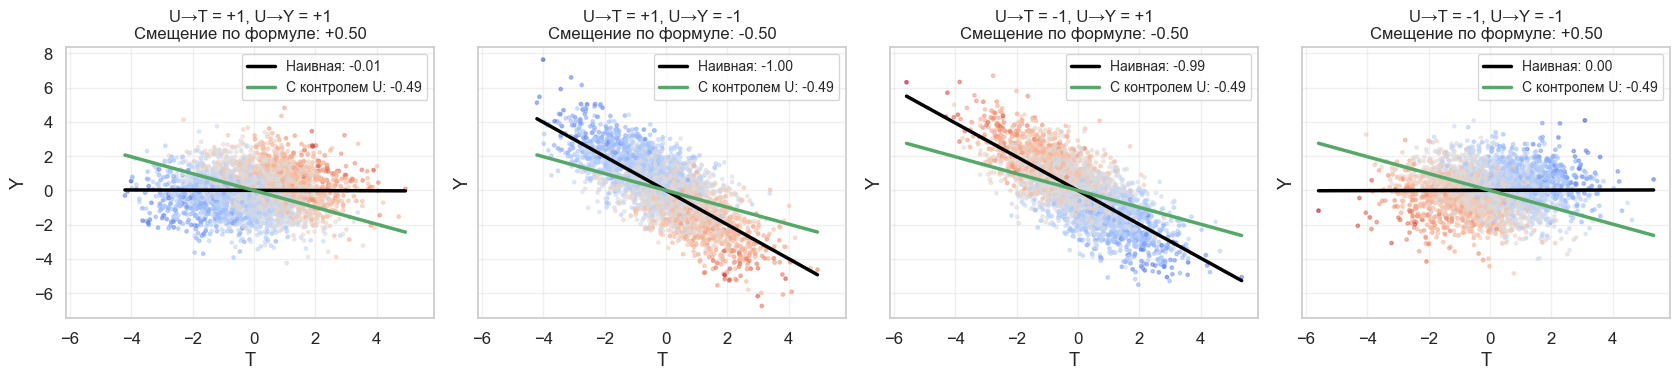

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, (u_t, u_y) in zip(axes, [(1, 1), (1, -1), (-1, 1), (-1, -1)]):
    plot_ovb(ax, u_t, u_y, -0.5)
    ax.set_title(f'U→T = {u_t:+d}, U→Y = {u_y:+d}\n{ax.get_title()}', fontsize=12)
plt.tight_layout()

Формула совпала с симуляцией: при одинаковых знаках смещение положительное, при разных отрицательное, а модель с $U$ всегда возвращает $-0.5$. При $U \to T = U \to Y = 1$ смещение меняет знак наблюдаемого эффекта, как в примере с полицией.

Графы показывают и то, как разные методы справляются с конфаундером. РКИ разрывает стрелку $W \to T$: если $T$ случайно, то ничто его не вызывает. Регрессия стрелки не разрывает: $W$ по-прежнему влияет на $T$ и $Y$, но мы сравниваем объекты при фиксированном $W$.

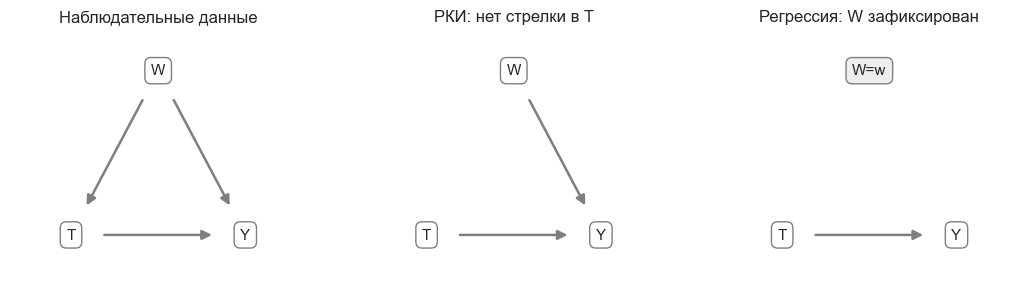

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
draw_dag(axes[0], [('W', 'T'), ('W', 'Y'), ('T', 'Y')], triangle, 'Наблюдательные данные')
draw_dag(axes[1], [('W', 'Y'), ('T', 'Y')], triangle, 'РКИ: нет стрелки в T')
draw_dag(axes[2], [('T', 'Y')], {'W=w': (0.5, 1), 'T': (0, 0), 'Y': (1, 0)}, 'Регрессия: W зафиксирован', fixed=('W=w',));

Вернёмся к вопросу о причинности оценки `educ`. Ответ зависит от того, можем ли мы аргументировать, что все конфаундеры в модели. Похоже, что нет. В ней нет семейного богатства, а образование родителей — лишь его косвенный показатель. Нет амбиций, которые могут вести и к более долгой учёбе, и к высокой зарплате. Поэтому **причинные выводы на наблюдательных данных всегда нужно воспринимать со скепсисом**: мы не можем быть уверены, что все конфаундеры учтены.

## Какие переменные включать в модель

Конфаундер в модель добавлять необходимо. Отсюда соблазн включить всё, что можно измерить. Как мы увидим, это не только не нужно, но и может сломать оценку.

### Полезные переменные

Вы работаете в отделе взыскания задолженности финтех-компании и оцениваете влияние письма с предложением обсудить условия погашения. Исход — сумма платежей от просроченных клиентов. Команда выбирает 5000 случайных клиентов и для каждого подбрасывает монетку: орёл — письмо, решка — контрольная группа.

In [16]:
email_data = pd.read_csv(DATA + 'confounded_df_one.csv')
email_data.head()

,payments,email,opened,agreement,credit_limit,risk_score
0,740,1,1.0,0.0,2348.495260,0.666752
1,580,1,1.0,1.0,334.111969,0.207395
2,600,1,1.0,1.0,1360.660722,0.550479
3,770,0,0.0,0.0,1531.828576,0.560488
4,660,0,0.0,0.0,979.855647,0.455140


Данные получены в эксперименте, поэтому $(Y_0, Y_1)\perp T$, и разница средних оценивает средний эффект:

$$
ATE = E[Y|T=1] - E[Y|T=0]
$$

Для интервала используем регрессию.

In [17]:
print('Разница средних:', round(email_data.query('email == 1')['payments'].mean() - email_data.query('email == 0')['payments'].mean(), 4))

model = smf.ols('payments ~ email', data=email_data).fit()
print(model.summary().tables[1])

Разница средних: -0.6203
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    669.9764      2.061    325.116      0.000     665.937     674.016
email         -0.6203      2.941     -0.211      0.833      -6.387       5.146


Оценка равна -0.62, p-value 0.83. Письмо вряд ли заставляет платить меньше: скорее всего, это шум. Значит ли это, что эксперимент не дал результата?

В данных есть `credit_limit` — кредитный лимит до просрочки — и `risk_score` — риск клиента до отправки письма. Логично предположить, что они хорошо предсказывают платежи. Посмотрим, зачем это нужно.

Письмо может иметь малый эффект, потому что платежи в основном зависят от другого: новой работы, дохода, финансовой дисциплины. **Большую часть изменчивости платежей объясняет не письмо.** На распределениях это хорошо видно.

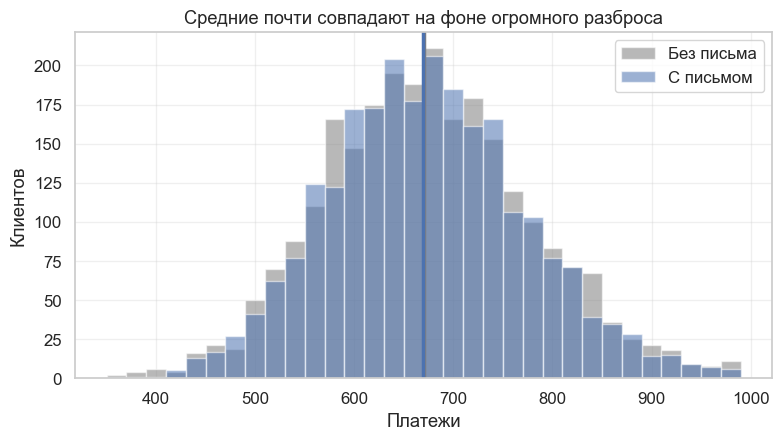

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for flag, color, label in [(0, GRAY, 'Без письма'), (1, BLUE, 'С письмом')]:
    group = email_data.query('email == @flag')['payments']
    ax.hist(group, bins=np.arange(350, 1000, 20), alpha=0.55, color=color, label=label)
    ax.axvline(group.mean(), color=color, lw=2.5)
ax.set_xlabel('Платежи')
ax.set_ylabel('Клиентов')
ax.set_title('Средние почти совпадают на фоне огромного разброса')
ax.legend();

Платежи в обеих группах лежат примерно от 400 до 1000. Если письмо даёт 5–10 реалов, неудивительно, что его трудно заметить.

Регрессия может снизить эту изменчивость. **Если переменная хорошо предсказывает исход, она объясняет большую часть его дисперсии.** У клиентов с похожими риском и лимитом платежи более похожи, поэтому эффект письма виден лучше.

Покажем это, разбив регрессию на два шага. Сначала регрессируем воздействие и исход на контроли, а затем остатки исхода на остатки воздействия. Это педагогическое упражнение: на практике достаточно одной регрессии.

Регрессия платежей на лимит и риск даёт новый исход с меньшей изменчивостью. Модель для письма, наоборот, не должна снижать дисперсию воздействия, потому что письмо случайно и предсказать его нельзя.

In [19]:
model_email = smf.ols('email ~ credit_limit + risk_score', data=email_data).fit()
model_payments = smf.ols('payments ~ credit_limit + risk_score', data=email_data).fit()

residuals = pd.DataFrame(dict(res_payments=model_payments.resid, res_email=model_email.resid))
model_treatment = smf.ols('res_payments ~ res_email', data=residuals).fit()

print('Дисперсия платежей:           ', round(email_data['payments'].var(), 1))
print('Дисперсия остатков платежей:  ', round(residuals['res_payments'].var(), 1))
print('Дисперсия письма:             ', round(email_data['email'].var(), 4))
print('Дисперсия остатков письма:    ', round(residuals['res_email'].var(), 4))
print(model_treatment.summary().tables[1])

Дисперсия платежей:            10809.8
Дисперсия остатков платежей:   5653.6
Дисперсия письма:              0.25
Дисперсия остатков письма:     0.2492
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    2.92e-14      1.063   2.75e-14      1.000      -2.084       2.084
res_email      4.4304      2.129      2.080      0.038       0.256       8.605


Дисперсия платежей упала с 10 810 до 5654, почти вдвое, а дисперсия письма не изменилась. Стандартная ошибка уменьшилась с 2.94 до 2.13.

Новая оценка равна 4.43 с p-value 0.038. Сдвиг от -0.62 к 4.43 — это не рост эффекта, а поправка на случайный дисбаланс групп. В контрольной группе лимит случайно оказался выше на 33.7, а каждая единица лимита добавляет 0.15 к платежам. Это даёт поправку около 5.

На гистограммах видно, что разброс внутри групп стал меньше.

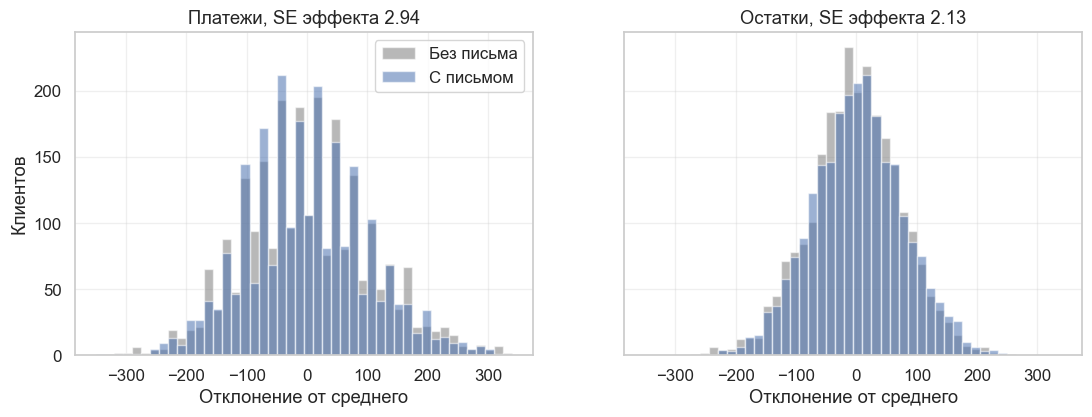

In [20]:
adjusted = email_data.assign(residual=model_payments.resid)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, values, title in [(axes[0], email_data['payments'] - email_data['payments'].mean(), f"Платежи, SE эффекта {model.bse['email']:.2f}"),
                          (axes[1], adjusted['residual'], f"Остатки, SE эффекта {model_treatment.bse['res_email']:.2f}")]:
    ax.hist(values[email_data['email'] == 0], bins=np.arange(-350, 350, 15), alpha=0.55, color=GRAY, label='Без письма')
    ax.hist(values[email_data['email'] == 1], bins=np.arange(-350, 350, 15), alpha=0.55, color=BLUE, label='С письмом')
    ax.set_title(title)
    ax.set_xlabel('Отклонение от среднего')
axes[0].set_ylabel('Клиентов')
axes[0].legend();

На практике контроли просто добавляют в одну регрессию вместе с воздействием, и оценка получается та же.

In [21]:
model_2 = smf.ols('payments ~ email + credit_limit + risk_score', data=email_data).fit()
print(model_2.summary().tables[1])
print('Корреляция credit_limit и risk_score:', round(email_data['credit_limit'].corr(email_data['risk_score']), 3))

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      490.8653      9.715     50.527      0.000     471.820     509.911
email            4.4304      2.130      2.080      0.038       0.255       8.606
credit_limit     0.1511      0.008     18.833      0.000       0.135       0.167
risk_score      -8.0516     38.424     -0.210      0.834     -83.379      67.276
Корреляция credit_limit и risk_score: 0.961


Если переменная хорошо предсказывает исход и измерена **до воздействия**, её стоит включать, даже если она не конфаундер. Это та же идея, что и в CUPED из лекции 1.04.

Здесь важны две оговорки.

* **Контроли нужно выбирать до просмотра результата.** В нашем рассказе мы увидели p = 0.83 и пошли искать контроли, после чего получили p = 0.038. Если перебирать наборы контролей, пока не появится значимость, это p-hacking, и p-value теряет смысл. В реальном тесте набор контролей фиксируют в дизайне.
* **Контролей здесь фактически один.** `credit_limit` и `risk_score` коррелируют на 0.96, поэтому `risk_score` в этой модели почти ничего не добавляет: его коэффициент незначим, а с одним `credit_limit` оценка почти та же.

Граф этой ситуации: у воздействия нет входящих стрелок, а контроли влияют только на исход.

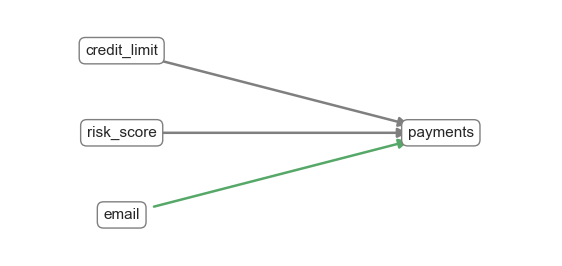

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.2))
draw_dag(ax, [('credit_limit', 'payments'), ('risk_score', 'payments'), ('email', 'payments', GREEN)],
         {'credit_limit': (0, 1), 'risk_score': (0, 0.5), 'email': (0, 0), 'payments': (1, 0.5)});

### Вредные переменные

Две больницы проводят рандомизированные испытания препарата. Исход — число дней госпитализации, поэтому эффективный препарат должен его снижать. Одна больница назначает препарат примерно 90% пациентов, другая примерно 10%. Больница с высокой долей препарата обычно получает более тяжёлые случаи.

In [23]:
hospital = pd.read_csv(DATA + 'confounded_df_two.csv')
hospital.groupby('hospital').agg(пациентов=('days', 'size'), доля_препарата=('treatment', 'mean'),
                                 тяжесть=('severity', 'mean'), дней=('days', 'mean')).round(2)

,пациентов,доля_препарата,тяжесть,дней
hospital,,,,
0,29,0.07,7.94,29.62
1,51,0.94,19.76,49.22


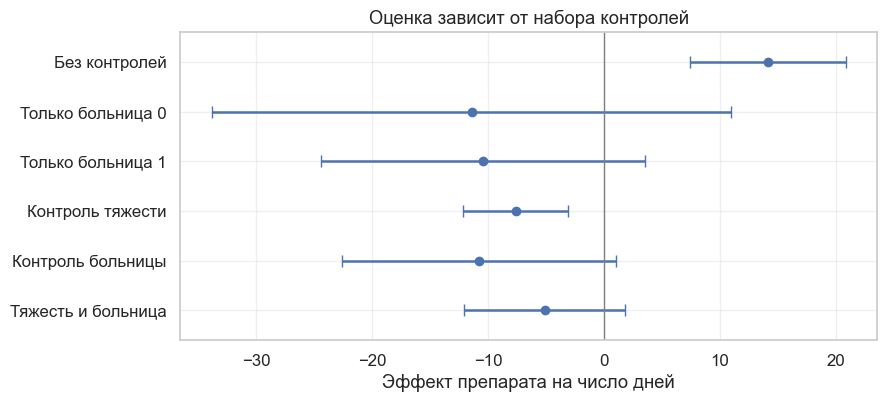

,Модель,Оценка,SE,ДИ 2.5%,ДИ 97.5%,p-value
0,Без контролей,14.153,3.367,7.451,20.856,0.000
1,Только больница 0,-11.407,10.921,-33.816,11.001,0.306
2,Только больница 1,-10.396,6.955,-24.371,3.580,0.141
3,Контроль тяжести,-7.591,2.269,-12.110,-3.073,0.001
4,Контроль больницы,-10.798,5.930,-22.607,1.011,0.073
5,Тяжесть и больница,-5.094,3.492,-12.049,1.861,0.149


In [24]:
hospital_table = pd.DataFrame([
    coef_row(smf.ols('days ~ treatment', hospital).fit(), 'treatment', 'Без контролей'),
    coef_row(smf.ols('days ~ treatment', hospital.query('hospital == 0')).fit(), 'treatment', 'Только больница 0'),
    coef_row(smf.ols('days ~ treatment', hospital.query('hospital == 1')).fit(), 'treatment', 'Только больница 1'),
    coef_row(smf.ols('days ~ treatment + severity', hospital).fit(), 'treatment', 'Контроль тяжести'),
    coef_row(smf.ols('days ~ treatment + hospital', hospital).fit(), 'treatment', 'Контроль больницы'),
    coef_row(smf.ols('days ~ treatment + severity + hospital', hospital).fit(), 'treatment', 'Тяжесть и больница'),
])

fig, ax = plt.subplots(figsize=(9, 4))
plot_forest(ax, hospital_table, 'Эффект препарата на число дней')
ax.set_title('Оценка зависит от набора контролей')
plt.show()
hospital_table.round(3)

Без контролей препарат «увеличивает» госпитализацию на 14 дней. Причина в том, что мы смешиваем два разных эксперимента. Препарат чаще получают в больнице с тяжёлыми пациентами, а тяжёлые лежат дольше: $E[Y_0|T=0]<E[Y_0|T=1]$.

Исправить это можно двумя способами. Первый — считать эффект внутри каждой больницы. Обе оценки отрицательны, около -11, но данных мало, и они незначимы. Второй — включить в модель тяжесть. Тогда оценка равна -7.6 с интервалом, не включающим ноль.

Нужно ли добавлять ещё и больницу? Она определяет вероятность препарата, но после учёта тяжести почти не связана с днями госпитализации. Такая переменная не снижает дисперсию исхода, зато отнимает вариацию у воздействия. В таблице видно, что SE выросла с 2.27 до 3.49.

Почему так? Для одного регрессора

$$
\hat{\sigma}^2 = \dfrac{1}{n-2} \sum( y_i - \hat{y}_i )^2, \qquad \text{Var}(\hat{\beta}) = \dfrac{\sigma^2}{\sum(x_i - \bar{x})^2}
$$

В множественной регрессии вместо $x$ в знаменателе стоит его остаток после всех остальных переменных:

$$
\text{Var}(\hat{\kappa}) = \dfrac{\sigma^2}{\sum \tilde{T}_i^2}
$$

Если воздействие почти не меняется, эффект оценить сложно. В пределе: тест на 10 000 человек, где препарат получил один, сравнивает его со всеми остальными. Больница хорошо предсказывает препарат, поэтому после её учёта вариации в воздействии остаётся мало. Проверим это двумя шагами.

In [25]:
model_treatment = smf.ols('treatment ~ severity + hospital', data=hospital).fit()
model_days = smf.ols('days ~ severity + hospital', data=hospital).fit()

residuals = pd.DataFrame(dict(res_days=model_days.resid, res_treatment=model_treatment.resid))
model_residuals = smf.ols('res_days ~ res_treatment', data=residuals).fit()
print(model_residuals.summary().tables[1])

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      3.828e-14      0.827   4.63e-14      1.000      -1.646       1.646
res_treatment    -5.0945      3.447     -1.478      0.143     -11.957       1.768


In [26]:
print('Дисперсия воздействия:           ', round(hospital['treatment'].var(), 4))
print('Дисперсия остатков воздействия:  ', round(residuals['res_treatment'].var(), 4))

Дисперсия воздействия:            0.2373
Дисперсия остатков воздействия:   0.0583


Дисперсия воздействия упала вчетверо, поэтому интервал и расширился.

Отсюда не следует, что больницу всегда надо выбрасывать. Здесь есть важный нюанс: препарат рандомизирован **внутри больницы**, поэтому именно больница — это дизайнерская переменная, и контроль только больницы даёт корректную оценку без дополнительных допущений. Он дал -10.8. Модель только с тяжестью точнее, но верна, только если больница не влияет на исход после учёта тяжести. Данные это не доказывают: коэффициент больницы равен -4.2 с интервалом от -12.9 до 4.6.

Проверим обе стороны на симуляции: 80 пациентов, настоящий эффект -10, в одном сценарии у больницы нет прямого эффекта, в другом он равен +10.

In [27]:
def simulate_hospitals(direct_effect, n_sims=4000, n=80, seed=7):
    """Сравнивает оценки препарата с разными контролями при известном эффекте -10."""
    local = np.random.default_rng(seed)
    results = {'Только тяжесть': [], 'Только больница': [], 'Тяжесть и больница': []}
    for _ in range(n_sims):
        hosp = (local.random(n) < 0.64).astype(float)
        severity = local.normal(8 + 12 * hosp, 4)
        treat = (local.random(n) < np.where(hosp == 1, 0.9, 0.1)).astype(float)
        days = 12 + 2.3 * severity - 10 * treat + direct_effect * hosp + local.normal(0, 8, n)
        for name, columns in [('Только тяжесть', [severity]), ('Только больница', [hosp]), ('Тяжесть и больница', [severity, hosp])]:
            design = np.column_stack([np.ones(n), treat] + columns)
            results[name].append(np.linalg.lstsq(design, days, rcond=None)[0][1])
    return {name: (np.mean(v), np.std(v)) for name, v in results.items()}


rows = []
for direct in [0, 10]:
    for name, (mean, sd) in simulate_hospitals(direct).items():
        rows.append({'Прямой эффект больницы': direct, 'Контроли': name, 'Средняя оценка': mean, 'Смещение': mean + 10, 'SD оценки': sd})
pd.DataFrame(rows).round(2)

,Прямой эффект больницы,Контроли,Средняя оценка,Смещение,SD оценки
0,0,Только тяжесть,-10.02,-0.02,2.49
1,0,Только больница,-9.97,0.03,4.99
2,0,Тяжесть и больница,-10.05,-0.05,3.28
3,10,Только тяжесть,-5.56,4.44,2.70
4,10,Только больница,-9.97,0.03,5.00
5,10,Тяжесть и больница,-10.05,-0.05,3.28


Если прямого эффекта нет, все три модели несмещены, а самая точная — модель только с тяжестью: SD 2.5 против 3.3. Если прямой эффект есть, модель только с тяжестью смещена на 4.4 дня, а модели с больницей остаются верными. Значит, отказ от контроля больницы — это ставка на допущение. Контроль стоит дороже по точности, но защищает от ошибки.

Итог такой:

* конфаундеры включать обязательно;
* хорошие предикторы исхода, измеренные до воздействия, включать полезно;
* переменные, которые предсказывают только воздействие, снижают точность, поэтому их лучше не добавлять, если нет уверенности, что других путей к исходу у них нет;
* переменную, по которой шла рандомизация, стоит учитывать в первую очередь.

### Плохие контроли

Вернёмся к письмам. `opened` показывает, открыл ли клиент письмо, а `agreement` — договорился ли он после этого с отделом взыскания. Какая модель лучше: с лимитом и риском или ещё и с этими двумя переменными?

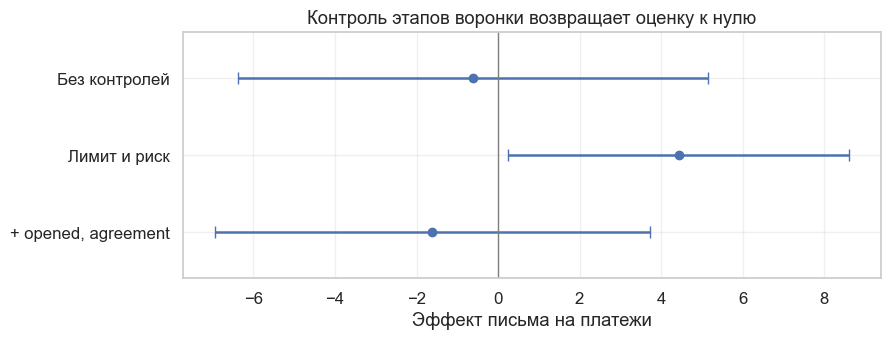

,Модель,Оценка,SE,ДИ 2.5%,ДИ 97.5%,p-value
0,Без контролей,-0.620,2.941,-6.387,5.146,0.833
1,Лимит и риск,4.430,2.130,0.255,8.606,0.038
2,"+ opened, agreement",-1.609,2.724,-6.949,3.730,0.555


In [28]:
email_models = pd.DataFrame([
    coef_row(smf.ols('payments ~ email', email_data).fit(), 'email', 'Без контролей'),
    coef_row(smf.ols('payments ~ email + credit_limit + risk_score', email_data).fit(), 'email', 'Лимит и риск'),
    coef_row(smf.ols('payments ~ email + credit_limit + risk_score + opened + agreement', email_data).fit(), 'email', '+ opened, agreement'),
])

fig, ax = plt.subplots(figsize=(9, 3.2))
plot_forest(ax, email_models, 'Эффект письма на платежи')
ax.set_title('Контроль этапов воронки возвращает оценку к нулю')
plt.show()
email_models.round(3)

Первая модель находит значимый эффект, вторая нет. Может быть, верна вторая, раз она учитывает больше факторов? Нет.

Конфаундеры добавлять обязательно. Хорошие предикторы исхода добавлять полезно. Переменные, предсказывающие только воздействие, лучше не добавлять. Но `opened` и `agreement` не относятся ни к одной из этих групп. Они связаны с письмом, потому что нельзя открыть письмо, которого нет. **Они не причина письма, а его следствие.**

Такие вопросы лучше решать с помощью графа.

       opened  agreement
email                   
0       0.000      0.000
1       0.557      0.328


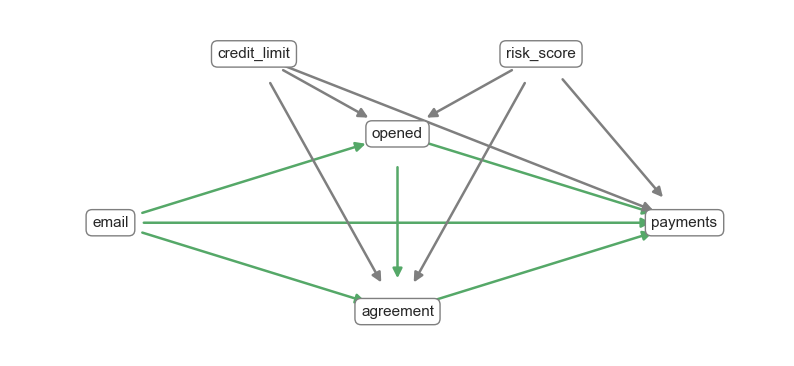

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
draw_dag(ax,
         [('email', 'payments', GREEN), ('email', 'opened', GREEN), ('email', 'agreement', GREEN), ('opened', 'payments', GREEN),
          ('opened', 'agreement', GREEN), ('agreement', 'payments', GREEN),
          ('credit_limit', 'payments'), ('credit_limit', 'opened'), ('credit_limit', 'agreement'),
          ('risk_score', 'payments'), ('risk_score', 'opened'), ('risk_score', 'agreement')],
         {'email': (0, 0.5), 'opened': (1, 1), 'agreement': (1, 0), 'payments': (2, 0.5), 'credit_limit': (0.5, 1.45), 'risk_score': (1.5, 1.45)})

print(email_data.groupby('email')[['opened', 'agreement']].mean().round(3))

Письмо случайно, поэтому в него не входит ни одна стрелка. Лимит и риск влияют на платежи. Письмо влияет на платежи, а также на `opened`. Люди с разным риском и лимитом по-разному открывают письма и договариваются. Исход можно представить как конец воронки:

$$
\text{письмо} \to \text{открыто} \to \text{соглашение} \to \text{оплата}
$$

Письмо может вести к соглашению и минуя `opened`: кому-то хватает темы письма.

Зелёные стрелки — это причинный путь от письма к платежам. `opened` и `agreement` лежат на нём, то есть это **медиаторы**. Если зафиксировать их, мы спрашиваем: «каков эффект письма при неизменном открытии и соглашении?» Но письмо, возможно, работает именно через них, и контроль убирает часть настоящего эффекта. Это называют **чрезмерным контролем (overcontrol)**.

Есть и вторая проблема. Рандомизация гарантирует $E[Y_0|T=0] = E[Y_0|T=1]$, но после фиксации `agreement` группы перестают быть сопоставимыми:

$$
E[Y_0|T=0, agreement=0] > E[Y_0|T=1, agreement=0]
$$

Среди тех, кто не договорился, в контроле находятся все подряд: у них просто не было письма. А в тесте остались те, кто не договорился **даже после письма**, и эти клиенты, вероятно, хуже. `agreement` здесь — общее следствие письма и скрытых свойств клиента, то есть **коллайдер** из лекции 2.07, и контроль открывает ложный путь.

Обратите внимание на вывод таблицы: в контрольной группе `opened` и `agreement` всегда равны нулю. Это несоблюдение условия перекрытия: при `agreement = 1` сравнивать не с кем, и регрессия просто экстраполирует.

Контроль общего следствия воздействия и исхода или воздействия и скрытых факторов называют **смещением отбора (selection bias)**. Смешивание (confounding) возникает, когда мы не контролируем общую причину, а смещение отбора — когда контролируем общее следствие. Контроль медиатора — это отдельная ошибка, хотя часто оба случая встречаются вместе.

Правило простое: **не включайте в модель ничего, на что могло повлиять воздействие.**

Вернёмся к зарплатам. Среди контролей, которые мы взяли в начале, `exper`, `tenure`, `married`, `urban` и `south` тоже могут зависеть от образования. Особенно это касается опыта: при одном возрасте кто дольше учился, тот меньше работал. Сравним только контроли, определённые до начала обучения, и добавление этих переменных.

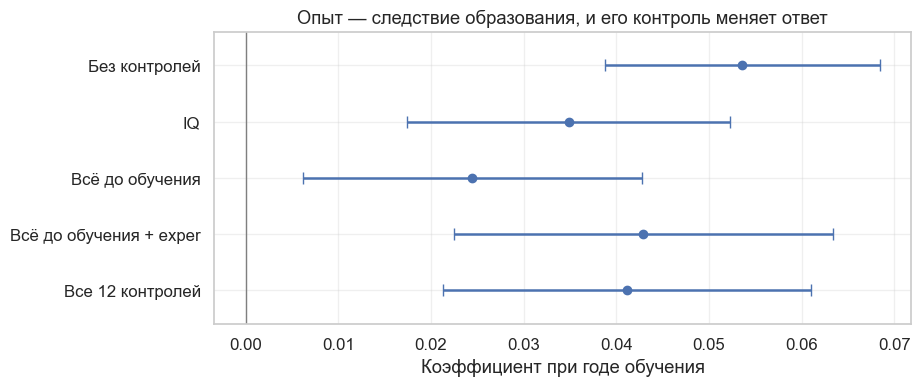

Корреляция educ и exper: -0.451


,Модель,Оценка,SE,ДИ 2.5%,ДИ 97.5%,p-value
0,Без контролей,0.0536,0.0075,0.0388,0.0684,0.0000
1,IQ,0.0349,0.0089,0.0174,0.0523,0.0001
2,Всё до обучения,0.0245,0.0093,0.0062,0.0427,0.0087
3,Всё до обучения + exper,0.0429,0.0104,0.0224,0.0634,0.0000
4,Все 12 контролей,0.0411,0.0101,0.0213,0.0610,0.0001


In [30]:
pre_treatment = ['IQ', 'age', 'black', 'sibs', 'brthord', 'meduc', 'feduc']

wage_models = pd.DataFrame([
    coef_row(smf.ols('lhwage ~ educ', wage).fit(), 'educ', 'Без контролей'),
    coef_row(smf.ols('lhwage ~ educ + IQ', wage).fit(), 'educ', 'IQ'),
    coef_row(smf.ols('lhwage ~ educ + ' + ' + '.join(pre_treatment), wage).fit(), 'educ', 'Всё до обучения'),
    coef_row(smf.ols('lhwage ~ educ + exper + ' + ' + '.join(pre_treatment), wage).fit(), 'educ', 'Всё до обучения + exper'),
    coef_row(smf.ols('lhwage ~ educ + ' + ' + '.join(controls), wage).fit(), 'educ', 'Все 12 контролей'),
])

fig, ax = plt.subplots(figsize=(9, 3.8))
plot_forest(ax, wage_models, 'Коэффициент при годе обучения')
ax.set_title('Опыт — следствие образования, и его контроль меняет ответ')
plt.show()

print('Корреляция educ и exper:', round(wage['educ'].corr(wage['exper']), 3))
wage_models.round(4)

С контролями, которые не могут зависеть от образования, оценка равна 2.5%, а не 4.1%. Добавление опыта возвращает её к 4.3%. Логика такая: учёба отнимает годы опыта, это отрицательный путь `educ → exper → wage`. Контроль опыта этот путь закрывает, и остаётся эффект образования «при том же опыте».

Это разные вопросы. Экономисты часто намеренно контролируют опыт, потому что хотят оценить отдачу при одном стаже, а не полный эффект. Важно понимать, на какой вопрос отвечает модель. Ни одна из этих оценок не причинная безусловно: все конфаундеры по-прежнему не измерены.

## Инструментальные переменные

Самый простой способ бороться с OVB — добавить пропущенную переменную в модель. Но часто данных по ней просто нет. Вернёмся к зарплатам:

$$
\log(\mathrm{wage})_i = \beta_0 + \kappa \ \mathrm{educ}_i + \pmb{\beta}\mathrm{Ability}_i + u_i
$$

Чтобы оценить $\kappa$, нужно контролировать способности, но надёжных измерений у нас нет. Лучшее, что есть, — сомнительные прокси вроде IQ.

Здесь помогают инструментальные переменные (IV). Нужна переменная $Z$, которая:

1. влияет на воздействие (**релевантность**);
2. не связана с конфаундерами (**независимость**): она как будто назначена случайно;
3. влияет на исход только через воздействие (**ограничение исключения**).

Условия 2 и 3 вместе означают, что $Z$ не коррелирует с $Y_0$.

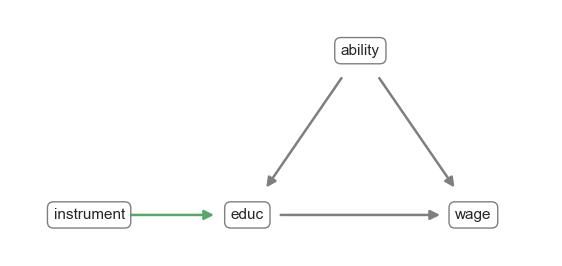

In [31]:
pos = {'ability': (1, 1), 'educ': (0.5, 0), 'wage': (1.5, 0), 'instrument': (-0.2, 0)}
edges = [('ability', 'educ'), ('ability', 'wage'), ('educ', 'wage'), ('instrument', 'educ', GREEN)]

fig, ax = plt.subplots(figsize=(7, 3.2))
draw_dag(ax, edges, pos);

Выпишем модель, которую хотим, используя $T$ для воздействия и $W$ для конфаундеров:

$$
Y_i = \beta_0 + \kappa \ T_i + \pmb{\beta}W_i + u_i
$$

$W$ нет в данных, поэтому мы можем оценить только

$$
Y_i = \beta_0 + \kappa\ T_i + v_i, \quad v_i = \pmb{\beta}W_i + u_i
$$

$W$ — конфаундер, поэтому $\mathrm{Cov}(T, v) \neq 0$, и обычная регрессия смещена. Но для инструмента $\mathrm{Cov}(Z,v) = 0$, иначе существовал бы второй путь из $Z$ в $Y$. Тогда

$$
\mathrm{Cov}(Z,Y) = \mathrm{Cov}(Z,\beta_0 + \kappa\ T_i + v_i) = \kappa \mathrm{Cov}(Z,T) + \mathrm{Cov}(Z, v) = \kappa \mathrm{Cov}(Z,T)
$$

Поделив обе части на $V(Z_i)$ и переставив члены, получаем:

$$
\kappa = \dfrac{\mathrm{Cov}(Y_i, Z_i)/V(Z_i)}{\mathrm{Cov}(T_i, Z_i)/V(Z_i)} = \dfrac{\text{Приведённая форма}}{\text{1-я стадия}}
$$

Числитель — коэффициент регрессии $Y$ на $Z$. Его называют **приведённой формой (reduced form)**. Это не значит, что $Z$ напрямую вызывает $Y$: он отражает влияние $Z$ на $Y$ через $T$. Знаменатель — коэффициент регрессии $T$ на $Z$, он называется **первой стадией (first stage)**.

То же самое можно записать через производные. Влияние $T$ на $Y$ равно влиянию $Z$ на $Y$, делённому на влияние $Z$ на $T$:

$$
\kappa = \dfrac{\partial y / \partial z}{\partial T / \partial z} = \dfrac{\partial y}{\partial z} \cdot \dfrac{\partial z}{\partial T} = \dfrac{\partial y}{\partial T}
$$

Идея в том, что влияние $T$ на $Y$ определить трудно из-за конфаундеров, а влияние $Z$ на $Y$ легко, потому что у них нет общих причин. Остаётся **перевести его в единицы $T$**, поделив на влияние $Z$ на $T$.

Если инструмент бинарный, получается отношение двух разниц средних. Его называют **оценкой Вальда**:

$$
\kappa = \dfrac{E[Y|Z=1]-E[Y|Z=0]}{E[T|Z=1]-E[T|Z=0]}
$$

### Квартал рождения и образование

Хорошие инструменты найти сложно. Классический пример — квартал рождения как инструмент для лет обучения.

Идея основана на законах США об обязательном обучении. Обычно ребёнку должно исполниться 6 лет к 1 января года поступления в школу, поэтому родившиеся в начале года поступают в более старшем возрасте. А бросить школу по закону можно в 16 лет. В результате родившиеся позже в году в среднем учатся чуть дольше.

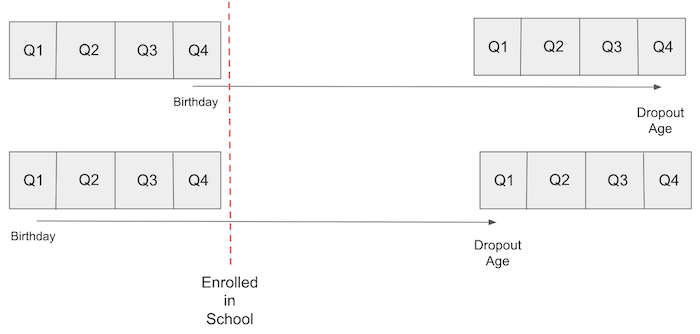

Если квартал рождения не связан со способностями и не влияет на зарплату иначе, чем через образование, его можно использовать как инструмент.

Граф такой же, как выше, а вместо `instrument` стоит `qob`.

Используем данные переписи 1980 года: мужчины 1930–1939 годов рождения, та же выборка, что в [статье Ангриста и Крюгера](https://economics.mit.edu/faculty/angrist/data1/data/angkru1991) (1991). В данных есть логарифм недельной зарплаты (исход), годы обучения (воздействие), квартал рождения (инструмент) и контроли: год и штат рождения.

In [32]:
data = pd.read_csv(DATA + 'iv_df.csv')
print(data.shape)
data.head()

(329509, 5)


,log_wage,years_of_schooling,year_of_birth,quarter_of_birth,state_of_birth
0,5.790019,12.0,30.0,1.0,45.0
1,5.952494,11.0,30.0,1.0,45.0
2,5.315949,12.0,30.0,1.0,45.0
3,5.595926,12.0,30.0,1.0,45.0
4,6.068915,12.0,30.0,1.0,37.0


### Первая стадия

Прежде чем использовать инструмент, нужно обосновать условия:

1. $\mathrm{Cov}(Z, T) \neq 0$ — сильная первая стадия. Это можно проверить.
2. $Z$ не связан с $Y_0$, то есть влияет на исход только через $T$. Это проверить нельзя.

Часто второе условие записывают как $Y \perp Z | T$, но это неверно. $T$ — общее следствие $Z$ и $U$, то есть коллайдер. Если зафиксировать $T$, откроется ложный путь $Z \to T \leftarrow U \to Y$, и зависимость появится даже у идеального инструмента. Проверим.

In [33]:
n = 200_000
u_demo = rng.normal(0, 2, n)
z_demo = rng.normal(0, 1, n)
t_demo = 1 + 0.5 * u_demo + z_demo + rng.normal(0, 2, n)
y_demo = 2 + 2 * t_demo - 2 * u_demo + rng.normal(0, 5, n)
demo = pd.DataFrame({'y': y_demo, 't': t_demo, 'z': z_demo})

print('Истинное прямое влияние Z на Y равно 0')
print('Коэффициент при Z в Y ~ T + Z:', round(smf.ols('y ~ t + z', demo).fit().params['z'], 3))

Истинное прямое влияние Z на Y равно 0
Коэффициент при Z в Y ~ T + Z: 0.814


Коэффициент при $Z$ не равен нулю, хотя инструмент идеален. Поэтому из регрессии $Y$ на $T$ и $Z$ нельзя проверить ограничение исключения.

Посмотрим на данные. Если всё работает, родившиеся в конце года должны иметь немного больше лет обучения.

In [34]:
group_data = (data
              .groupby(['year_of_birth', 'quarter_of_birth'])
              [['log_wage', 'years_of_schooling']]
              .mean()
              .reset_index()
              .assign(time_of_birth=lambda d: d['year_of_birth'] + d['quarter_of_birth'] / 4))

QUARTER_COLORS = {1: RED, 2: GRAY, 3: GRAY, 4: GREEN}


def plot_by_quarter(ax, column, ylabel, title):
    """Рисует средние по когортам и подписывает номер квартала."""
    ax.plot(group_data['time_of_birth'], group_data[column], color=GRAY, lw=1, zorder=1)
    for quarter, color in QUARTER_COLORS.items():
        part = group_data.query('quarter_of_birth == @quarter')
        ax.scatter(part['time_of_birth'], part[column], marker='s', s=170, color=color, zorder=2)
        ax.scatter(part['time_of_birth'], part[column], marker=f'${quarter}$', s=70, color='white', zorder=3)
    ax.set_xlabel('Год рождения')
    ax.set_ylabel(ylabel)
    ax.set_title(title)

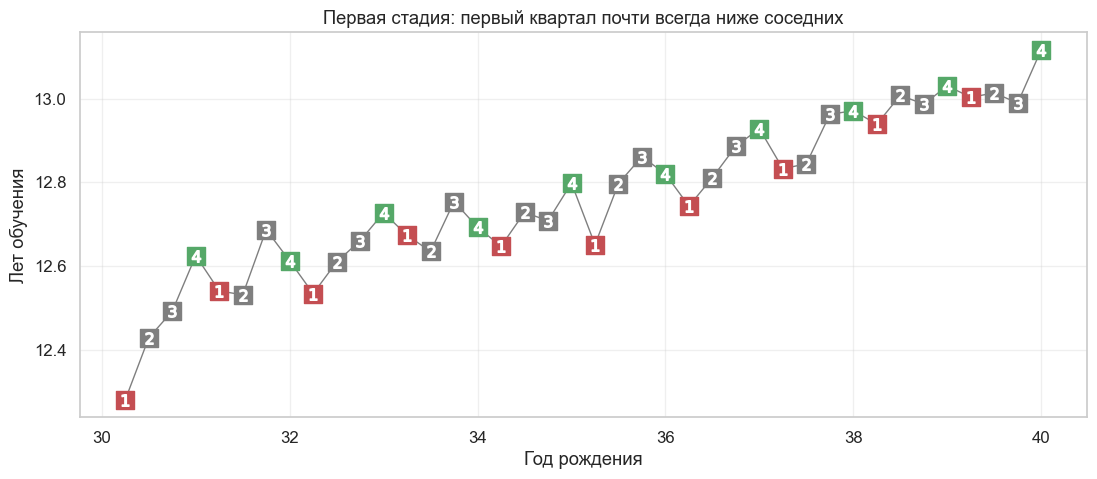

In [35]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_by_quarter(ax, 'years_of_schooling', 'Лет обучения', 'Первая стадия: первый квартал почти всегда ниже соседних');

Виден сезонный рисунок: первый квартал почти всегда ниже соседних. Для родившихся позже общий уровень образования выше, поэтому просто сравнивать кварталы разных лет нельзя.

Точнее оценим первую стадию регрессией. Преобразуем квартал в бинарные переменные и для простоты возьмём только последний квартал `q4`. В модель также добавим год и штат рождения.

Для простоты пока будем использовать в качестве инструмента только последний квартал, q4. Мы построим регрессию продолжительности обучения (воздействие) на квартал рождения (инструмент). Это покажет, действительно ли квартал рождения положительно влияет на время обучения, как мы видели на графике выше. Здесь также необходимо учитывать год рождения, и мы добавим штат рождения в качестве дополнительного контрольного фактора.

In [36]:
factor_data = data.assign(**{f'q{int(q)}': (data['quarter_of_birth'] == q).astype(int) for q in data['quarter_of_birth'].unique()})

first_stage = smf.ols('years_of_schooling ~ C(year_of_birth) + C(state_of_birth) + q4', data=factor_data).fit()

print('Коэффициент q4:', round(first_stage.params['q4'], 4))
print('p-value:', first_stage.pvalues['q4'])
print('F-статистика инструмента:', round(first_stage.tvalues['q4'] ** 2, 1))
print('Частный R2 инструмента:', round(first_stage.tvalues['q4'] ** 2 / (first_stage.tvalues['q4'] ** 2 + first_stage.df_resid), 5))

Коэффициент q4: 0.1009
p-value: 5.4648294165921045e-15
F-статистика инструмента: 61.1
Частный R2 инструмента: 0.00019


Родившиеся в последнем квартале учатся в среднем на 0.1 года дольше. Эффект мал, но выборка огромна, поэтому p-value близко к нулю. F-статистика равна 61. Позже мы увидим, зачем на неё смотреть.

### Приведённая форма

Второе условие проверить нельзя, можно только аргументировать. Квартал рождения кажется почти случайным: календарь не должен определять способности.

Но это не бесспорно. Он случаен не полностью, и [Баклс и Хангерман (2013)](https://www.nber.org/papers/w14573) показали, что зимние дети чаще рождаются у матерей моложе, незамужних и с меньшим образованием. Семейные характеристики объясняют значительную часть связи сезона рождения с результатами во взрослом возрасте. Значит, ограничение исключения может нарушаться, а оценки IV могут быть несостоятельны.

Посмотрим, как инструмент влияет на исход.

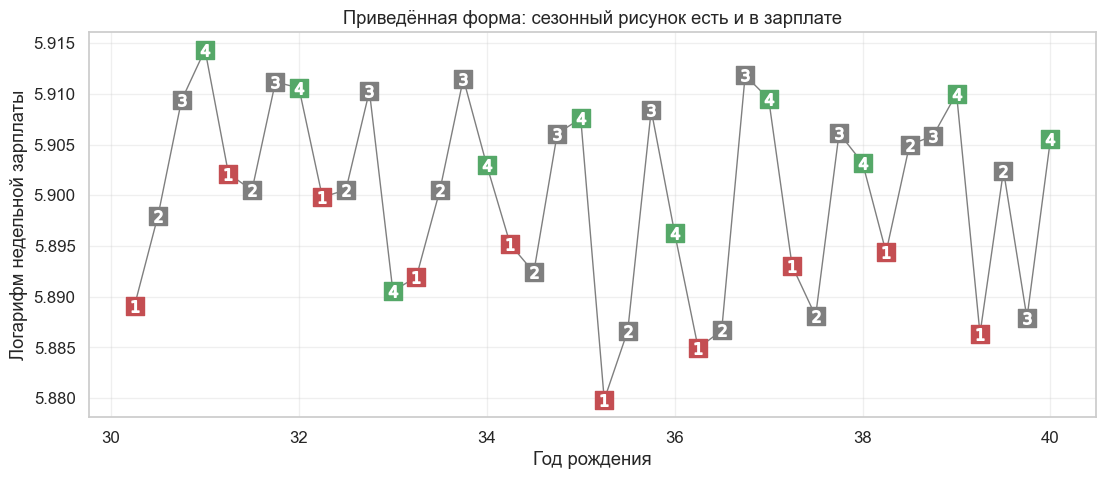

In [37]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_by_quarter(ax, 'log_wage', 'Логарифм недельной зарплаты', 'Приведённая форма: сезонный рисунок есть и в зарплате');

Сезонный рисунок есть и здесь, но зарплата растёт с возрастом, и тренд его скрывает. Проверим регрессией с теми же контролями, что и на первой стадии.

In [38]:
reduced_form = smf.ols('log_wage ~ C(year_of_birth) + C(state_of_birth) + q4', data=factor_data).fit()

print('Коэффициент q4:', round(reduced_form.params['q4'], 4))
print('p-value:', round(reduced_form.pvalues['q4'], 4))

Коэффициент q4: 0.0086
p-value: 0.0015


У родившихся в последнем квартале зарплата в среднем примерно на 0.9% выше, p-value равно 0.0015.

### Инструментальные переменные вручную

Разделим приведённую форму на первую стадию. Коэффициент первой стадии около 0.1, поэтому приведённая форма умножится почти на 10:

$$
\kappa_{IV} = \dfrac{\text{Приведённая форма}}{\text{1-я стадия}}
$$

In [39]:
reduced_form.params['q4'] / first_stage.params['q4']

np.float64(0.08530286492086271)

Каждый дополнительный год обучения увеличивает зарплату примерно на 8.5%.

Эта оценка **состоятельна, но смещена** в конечной выборке, и это не ATE в общем случае. Подробнее об обоих пунктах ниже.

Другой способ получить оценку — **двухшаговый МНК (2SLS)**. Сначала оцениваем первую стадию, а затем подставляем её прогноз вместо воздействия:

$$
\mathrm{educ}_i = \gamma_0 + \gamma_1 \times \mathrm{q4}_i + \gamma_2\times \mathrm{yob}_i + \gamma_3\times \mathrm{sob}_i + v_i
$$

$$
\log(\mathrm{wage})_i = \beta_0 + \beta_1\times \widehat{\mathrm{educ}}_i + \beta_2\times \mathrm{yob}_i + \beta_3\times \mathrm{sob}_i + u_i
$$

**Любой контроль второго этапа должен входить и в первый.**

In [40]:
iv_by_hand = smf.ols('log_wage ~ C(year_of_birth) + C(state_of_birth) + years_of_schooling_fitted',
                     data=factor_data.assign(years_of_schooling_fitted=first_stage.fittedvalues)).fit()

print('Оценка:', round(iv_by_hand.params['years_of_schooling_fitted'], 5))
print('SE второго шага (неверная):', round(iv_by_hand.bse['years_of_schooling_fitted'], 5))

Оценка: 0.0853
SE второго шага (неверная): 0.02686


Параметр тот же. Интуиция 2SLS в том, что первый этап создаёт версию воздействия, очищенную от смещения.

Но вручную IV не считают: стандартная ошибка второго шага не учитывает, что прогноз сам оценён, и она неверна. В Python для этого есть библиотека [linearmodels](https://bashtage.github.io/linearmodels/).

В формуле первая стадия пишется в квадратных скобках: `[years_of_schooling ~ q4]`. Контроли вне скобок автоматически попадают на первый этап.

In [41]:
def show_iv(model, exog='years_of_schooling'):
    low, high = model.conf_int().loc[exog]
    print(f'Оценка: {model.params[exog]:.4f}, SE: {model.std_errors[exog]:.4f}, 95% ДИ: [{low:.4f}, {high:.4f}], p-value: {model.pvalues[exog]:.2g}')


formula = 'log_wage ~ 1 + C(year_of_birth) + C(state_of_birth) + [years_of_schooling ~ q4]'
iv2sls = IV2SLS.from_formula(formula, factor_data).fit()
show_iv(iv2sls)

Оценка: 0.0853, SE: 0.0255, 95% ДИ: [0.0352, 0.1354], p-value: 0.00084


Параметр тот же, а стандартная ошибка 0.0255 уже корректна и чуть меньше той, что дал второй шаг. Здесь она учитывает гетероскедастичность.

### Множественные инструменты

Готовая реализация позволяет легко добавить несколько инструментов. Возьмём все три бинарных индикатора квартала.

In [42]:
formula = 'log_wage ~ 1 + C(year_of_birth) + C(state_of_birth) + [years_of_schooling ~ q1 + q2 + q3]'
iv_many_zs = IV2SLS.from_formula(formula, factor_data).fit()
show_iv(iv_many_zs)

Оценка: 0.1077, SE: 0.0196, 95% ДИ: [0.0694, 0.1460], p-value: 3.7e-08


Теперь оценка равна 0.108, то есть примерно 11% за год обучения. Сравним с обычным МНК.

In [43]:
formula = 'log_wage ~ years_of_schooling + C(state_of_birth) + C(year_of_birth) + C(quarter_of_birth)'
ols = IV2SLS.from_formula(formula, data=data).fit()
show_iv(ols)

Оценка: 0.0673, SE: 0.0004, 95% ДИ: [0.0666, 0.0681], p-value: 0


МНК даёт 6.7%, а 2SLS 8.5–10.8%. Было бы естественно ожидать обратного, если главная проблема — положительное смещение из-за способностей. Как это можно объяснить:

* МНК занижается из-за ошибок измерения образования;
* IV оценивает эффект не для всех, а для тех, на кого действует инструмент: людей, которые бросили бы школу при первой возможности. У них отдача от учёбы может быть выше. Такое объяснение обсуждает, например, Кард (1999);
* интервалы широкие: у 2SLS с одним инструментом он равен [0.035, 0.135] и содержит оценку МНК;
* ограничение исключения может нарушаться, как мы видели выше.

### Слабые инструменты

IV оценивает эффект косвенно, через первую стадию. Если инструмент слабо связан с воздействием, мы мало что можем узнать. Формулы для SE здесь неинтуитивны, поэтому используем симуляцию с настоящим эффектом 2:

$$
\begin{align}
Z \sim & N(0, 1)\\
U \sim & N(0, 2^2)\\
T \sim & N(1 + 0.5U + \gamma Z, 2^2)\\
Y \sim & N(2 - 2U + 2T, 5^2)
\end{align}
$$

Параметр $\gamma$ задаёт силу первой стадии.

Важная деталь: инструмент нельзя строить как зашумлённую копию воздействия, $Z = T + \varepsilon$. Такой $Z$ наследует связь с $U$ через $T$, нарушает независимость и даёт не эффект, а оценку МНК при любом шуме.

In [44]:
n = 200_000
u_big = rng.normal(0, 2, n)
t_big = 1 + 0.5 * u_big + rng.normal(0, 2, n)
y_big = 2 - 2 * u_big + 2 * t_big + rng.normal(0, 5, n)

print('Настоящий эффект: 2')
print('МНК:', round(np.cov(t_big, y_big)[0, 1] / t_big.var(ddof=1), 3))
for noise in [1, 5, 20]:
    z_bad = t_big + rng.normal(0, noise, n)
    print(f'IV c Z = T + шум (sd = {noise}):', round(np.cov(z_bad, y_big)[0, 1] / np.cov(z_bad, t_big)[0, 1], 3))

Настоящий эффект: 2
МНК: 1.185
IV c Z = T + шум (sd = 1): 1.181
IV c Z = T + шум (sd = 5): 1.211
IV c Z = T + шум (sd = 20): 1.151


In [45]:
def simulate_iv(gamma, n=1000, reps=2000, seed=0):
    """Возвращает оценки IV и МНК и F-статистики первой стадии по многим симуляциям."""
    local = np.random.default_rng(seed)
    u = local.normal(0, 2, (reps, n))
    z = local.normal(0, 1, (reps, n))
    t = 1 + 0.5 * u + gamma * z + local.normal(0, 2, (reps, n))
    y = 2 - 2 * u + 2 * t + local.normal(0, 5, (reps, n))

    z_c, t_c, y_c = [v - v.mean(axis=1, keepdims=True) for v in (z, t, y)]
    iv = (z_c * y_c).sum(axis=1) / (z_c * t_c).sum(axis=1)
    ols_est = (t_c * y_c).sum(axis=1) / (t_c ** 2).sum(axis=1)
    r2 = (z_c * t_c).sum(axis=1) ** 2 / ((z_c ** 2).sum(axis=1) * (t_c ** 2).sum(axis=1))
    return iv, ols_est, r2 * (n - 2) / (1 - r2)


def plot_iv(ax, gamma, n=1000):
    iv, ols_est, f_stat = simulate_iv(gamma, n)
    ax.hist(np.clip(iv, -3, 7), bins=np.linspace(-3, 7, 61), color=BLUE, alpha=0.75)
    ax.axvline(2, color=GREEN, lw=2.5, label='Истинный эффект')
    ax.axvline(np.median(ols_est), color=RED, lw=2.5, label='МНК')
    ax.axvline(np.median(iv), color='black', ls='--', lw=2, label='Медиана IV')
    ax.set_title(f'γ = {gamma}, средняя F = {f_stat.mean():.0f}', fontsize=12)
    ax.set_xlabel('Оценка эффекта')


def iv_demo(gamma=0.1, n=1000):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    plot_iv(ax, gamma, n)
    ax.legend()
    plt.show()


interact(iv_demo,
         gamma=FloatSlider(value=0.1, min=0.02, max=1, step=0.02, description='Сила γ'),
         n=IntSlider(value=1000, min=200, max=3000, step=200, description='Размер n'));

Статичная версия для трёх значений силы инструмента. Значения вне диапазона от -3 до 7 собраны на краях графика.

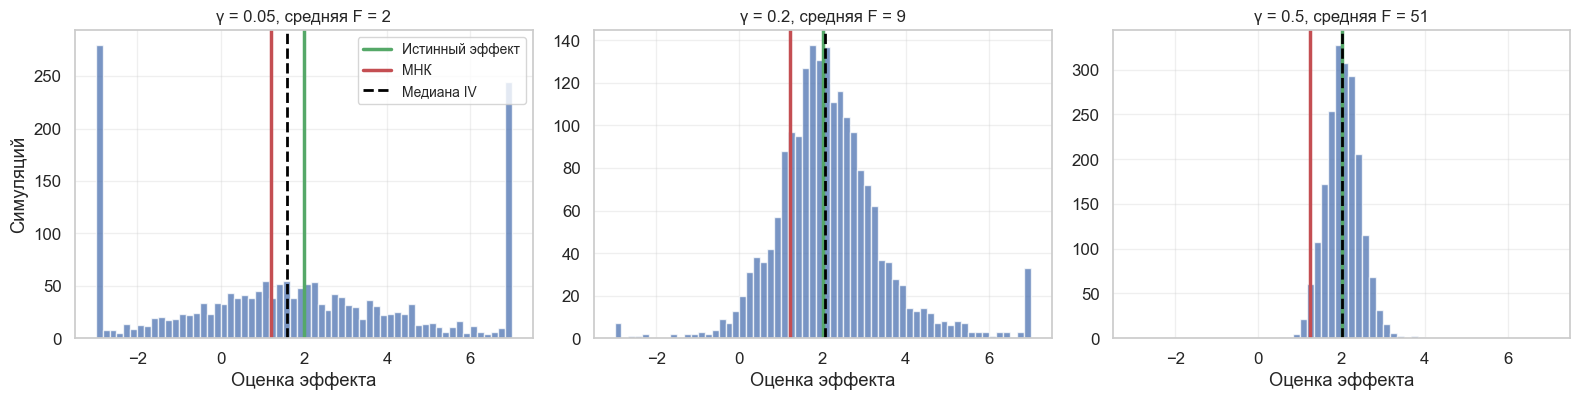

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
for ax, gamma in zip(axes, [0.05, 0.2, 0.5]):
    plot_iv(ax, gamma)
axes[0].set_ylabel('Симуляций')
axes[0].legend(fontsize=10)
plt.tight_layout()

In [47]:
rows = []
for gamma in [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    iv, ols_est, f_stat = simulate_iv(gamma)
    rows.append({'γ': gamma, 'Средняя F': f_stat.mean(), 'Медиана IV': np.median(iv),
                 'Смещение медианы': np.median(iv) - 2, 'Межквартильный размах': np.subtract(*np.percentile(iv, [75, 25])),
                 'Медиана МНК': np.median(ols_est)})
pd.DataFrame(rows).round(2)

,γ,Средняя F,Медиана IV,Смещение медианы,Межквартильный размах,Медиана МНК
0,0.02,1.11,1.38,-0.62,5.27,1.20
1,0.05,1.52,1.60,-0.40,4.29,1.20
2,0.10,3.02,1.91,-0.09,2.77,1.20
3,0.20,9.01,2.05,0.05,1.40,1.21
4,0.50,51.05,2.02,0.02,0.54,1.24
5,1.00,201.30,2.01,0.01,0.27,1.33


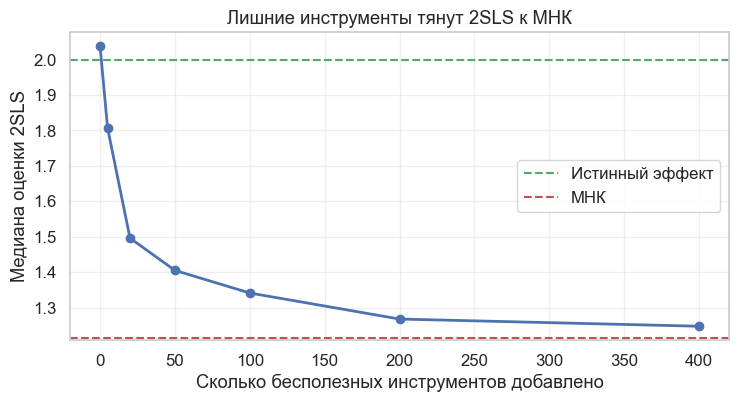

In [48]:
def tsls_many(n_extra, n=1000, reps=300, gamma=0.3, seed=3):
    """Считает медиану 2SLS, когда к инструменту добавлено n_extra бесполезных."""
    local = np.random.default_rng(seed)
    estimates = []
    for _ in range(reps):
        u = local.normal(0, 2, n)
        z = local.normal(0, 1, (n, n_extra + 1))
        t = 1 + 0.5 * u + gamma * z[:, 0] + local.normal(0, 2, n)
        y = 2 - 2 * u + 2 * t + local.normal(0, 5, n)
        z_c, t_c, y_c = z - z.mean(axis=0), t - t.mean(), y - y.mean()
        fitted = z_c @ np.linalg.lstsq(z_c, t_c, rcond=None)[0]
        estimates.append((fitted @ y_c) / (fitted @ t_c))
    return np.median(estimates)


extra = [0, 5, 20, 50, 100, 200, 400]
medians = [tsls_many(k) for k in extra]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(extra, medians, 'o-', color=BLUE, lw=2)
ax.axhline(2, color=GREEN, ls='--', label='Истинный эффект')
ax.axhline(2 - 2 * 2 / 5.09, color=RED, ls='--', label='МНК')
ax.set_xlabel('Сколько бесполезных инструментов добавлено')
ax.set_ylabel('Медиана оценки 2SLS')
ax.set_title('Лишние инструменты тянут 2SLS к МНК')
ax.legend();

Настоящий эффект равен 2, МНК даёт около 1.2.

* При средней $F$ от 1 до 2 медиана IV сдвинута к МНК: 1.38–1.60. Половина оценок разбросана в полосе шириной 4–5, а отдельные оценки вообще не имеют смысла: они собраны на краях левого графика.
* При $F = 9$ медиана уже рядом с истиной, но разброс всё ещё велик: межквартильный размах 1.4.
* При $F = 51$ размах равен 0.54, и большинство оценок лежит заметно правее МНК.

На графике выше добавлены инструменты, которые не влияют на воздействие вообще. Медиана 2SLS падает с 2.04 до 1.25, почти до МНК. Со слишком большим числом инструментов первый этап начинает подгонять шум, и прогноз $\hat{T}$ становится похож на само $T$ вместе с его смещением.

Практические правила:

1. **2SLS смещён в сторону МНК.** Метод состоятелен, то есть приближается к истине с ростом выборки, в отличие от МНК при OVB. Но на конечной выборке при слабом инструменте смещение есть.
2. **Смещение растёт с числом слабых инструментов.** Именно на этом основана критика [Баунда, Джегера и Бейкера (1995)](https://research-portal.st-andrews.ac.uk/en/publications/problems-with-instrumental-variables-estimation-when-the-correlat/): заменив кварталы рождения случайными числами в спецификациях Ангриста — Крюгера с множеством взаимодействий, они получили оценки, близкие к МНК.
3. **Смотрите на F-статистику первой стадии.** Старое правило требует $F > 10$. Но [Ли и др. (2022)](https://arxiv.org/abs/2010.05058) показали, что для настоящего 5% уровня t-теста нужно $F > 104.7$, а при $F$ около 10 критическое значение следует поднять с 1.96 до 3.43. Наша F = 61 для `q4` проходит старое правило, но не новое.

Две частые ошибки:

1. **Считать IV вручную.** Точечная оценка будет верной, а SE нет.
2. **Подставлять на второй этап прогноз логистической регрессии.** Состоятельность 2SLS опирается на то, что остатки линейной первой стадии ортогональны контролям и прогнозу. Если подставить прогноз нелинейной модели прямо на второй шаг, эта гарантия пропадает, если нелинейная модель неверна. Это называют запрещённой регрессией. Такой прогноз можно использовать как инструмент, а не как замену воздействию. Существуют и корректные методы с ML, например DML для IV, но у них свои предположения.

## Несоблюдение назначения

### Гетерогенный мир

Современный подход к IV делит объекты на четыре типа по реакции на инструмент. Он идёт от работ Имбенса, Ангриста и Рубина 1990-х годов, а названия пришли из медицинских испытаний:

1. Соблюдающие (Compliers) принимают то, что им назначили: лекарство или плацебо.
2. Никогда не принимающие (Never Takers) отказываются от лекарства, даже если оно назначено.
3. Всегда принимающие (Always Takers) находят способ получить лекарство, даже если назначено плацебо.
4. Поступающие наоборот (Defiers) делают противоположное назначенному. На практике их обычно считают отсутствующими.

Инструмент здесь рассматривается как эксперимент с неидеальным соблюдением. Это разводит внутреннюю и внешнюю валидность. **Внутренняя валидность** означает, что эффект корректно оценён в этих условиях на этих данных. В IV это эффект для тех, чьё воздействие меняется под действием инструмента. **Внешняя валидность** означает, что результат можно перенести на другие популяции. Если вы проверили щедрость на студентах-экономистах и они оказались эгоистами, вывод верен для этих студентов, но не для всего человечества.

Рассмотрим пример. Вы хотите повысить покупки в приложении с помощью push-уведомлений. Вы выбираете 10 000 клиентов и назначаете push с вероятностью 50%. При проведении теста оказывается, что часть назначенных уведомлений не доходит: у этих клиентов старые телефоны, не поддерживающие этот тип push.

Можно ли просто заменить назначенное воздействие на полученное? Нарисуем граф.

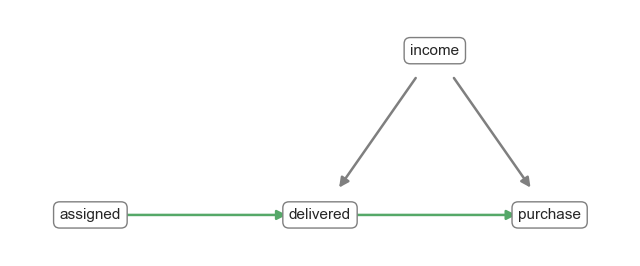

In [49]:
fig, ax = plt.subplots(figsize=(8, 3.2))
draw_dag(ax, [('assigned', 'delivered', GREEN), ('delivered', 'purchase', GREEN), ('income', 'purchase'), ('income', 'delivered')],
         {'assigned': (0, 0), 'delivered': (1, 0), 'purchase': (2, 0), 'income': (1.5, 1)});

Назначение (`assigned`) случайно, в него не входят стрелки. Доставка (`delivered`) меняется не только от назначения: чем выше доход `income`, тем новее телефон и тем вероятнее доставка. Доход влияет и на покупки, а данных о доходе у нас нет.

**Вариант 1: сравнить по назначению.**

$$
E[Y | assigned=1] - E[Y | assigned=0]
$$

Назначение случайно, поэтому смещения нет. Но это ответ на другой вопрос: мы получим **эффект намерения назначить (Intention-To-Treat, ITT)**, а не эффект самого уведомления.

Несоблюдение размывает разницу между группами. Если кто-то из контроля всё равно получает воздействие, контроль становится смесью обеих групп.

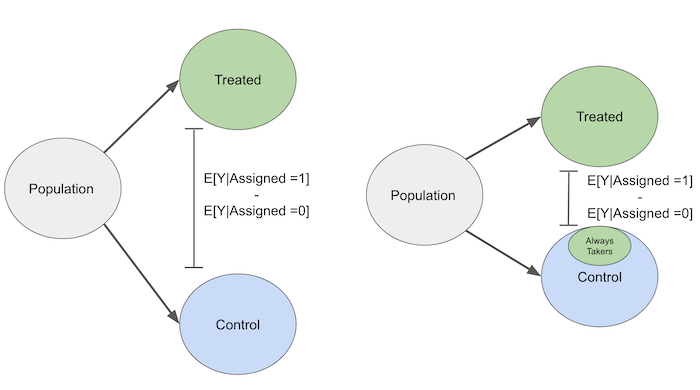

Те, кто не принимает воздействие в тесте, тоже похожи на контроль. Поэтому **ITT смещён к нулю относительно эффекта воздействия**. В крайнем случае, если назначение ничего не говорит о получении, первая стадия равна нулю, и

$$
E[Y|Z=1] - E[Y|Z=0] = 0
$$

При этом ITT — это полезная величина. Она отвечает на вопрос бизнеса: сколько мы получим, если включим такую рассылку для всех, с учётом всех недоставленных уведомлений.

**Вариант 2: сравнить по доставке.**

$$
E[Y | delivered=1] - E[Y | delivered=0]
$$

Здесь есть неучтённый доход. Вероятно, $E[Y_0|delivered=0] < E[Y_0|delivered=1]$: у клиентов с меньшим бюджетом старые телефоны и меньше покупок.

Ни один из вариантов не даёт эффект доставки. Но у нас есть готовый инструмент: назначение случайно и влияет на покупки только через доставку.

### Local Average Treatment Effect

В современной трактовке цепочка выглядит так: $Z$ вызывает $T$, а $T$ вызывает $Y$. Пусть $T_{1i}$ и $T_{0i}$ — потенциальное воздействие при $Z=1$ и $Z=0$, а в потенциальном исходе первый индекс обозначает воздействие, второй — инструмент:

$$
\text{Потенциальный исход}=\begin{cases}
Y_i(1, 1) \ \text{if } T_i=1, \ Z_i=1\\
Y_i(1, 0) \ \text{if } T_i=1, \ Z_i=0\\
Y_i(0, 1) \ \text{if } T_i=0, \ Z_i=1\\
Y_i(0, 0) \ \text{if } T_i=0, \ Z_i=0\\
\end{cases}
$$

Условия для инструмента:

* **Независимость** — $(Y_i(t, z), T_{1i}, T_{0i}) \perp Z_i$. Инструмент назначен как будто случайно, то есть группы с разным $Z$ сравнимы и по потенциальным исходам, и по реакции на инструмент.

* **Ограничение исключения** — $Y_i(1, 0)=Y_i(1, 1)=Y_{1i}$ и $Y_i(0, 0)=Y_i(0, 1)=Y_{0i}$. Инструмент влияет на исход только через воздействие.

* **Наличие первой стадии** — $E[T_{1i}-T_{0i}] \neq 0$. Инструмент действительно влияет на воздействие.

* **Монотонность** — $T_{1i} \geq T_{0i}$ для всех $i$. Инструмент никого не сдвигает в обратную сторону, то есть нет поступающих наоборот.

Разберём оценку Вальда:

$$
\kappa_{IV} = \dfrac{E[Y|Z=1]-E[Y|Z=0]}{E[T|Z=1]-E[T|Z=0]}
$$

По ограничению исключения

$$
E[Y_i|Z_i=1]=E[Y_{0i} + T_{1i}(Y_{1i} - Y_{0i})|Z=1]
$$

По независимости условие на $Z$ можно убрать:

$$
E[Y_i|Z_i=1]=E[Y_{0i} + T_{1i}(Y_{1i} - Y_{0i})]
$$

Аналогично

$$
E[Y_i|Z_i=0]=E[Y_{0i} + T_{0i}(Y_{1i} - Y_{0i})]
$$

Числитель равен

$$
E[Y|Z=1]-E[Y|Z=0] = E[(Y_{1i}-Y_{0i})(T_{1i}-T_{0i})]
$$

По монотонности $T_{1i}-T_{0i}$ равно 0 или 1, поэтому

$$
E[(Y_{1i}-Y_{0i})(T_{1i}-T_{0i})] = E[Y_{1i}-Y_{0i}|T_{1i}>T_{0i}]P(T_{1i}>T_{0i})
$$

Знаменатель равен

$$
E[T|Z=1]-E[T|Z=0]=E[T_{1i}-T_{0i}]=P(T_{1i}>T_{0i})
$$

В итоге

$$
\kappa_{IV} = \dfrac{E[Y_{1i}-Y_{0i}|T_{1i}>T_{0i}]P(T_{1i}>T_{0i})}{P(T_{1i}>T_{0i})}=E[Y_{1i}-Y_{0i}|T_{1i}>T_{0i}]
$$

Группа $T_{1i}>T_{0i}$ — это соблюдающие. **IV оценивает эффект только для них.** Про остальных он ничего не говорит, потому что их воздействие инструмент не меняет. Это и есть LATE. Поэтому обозначение ATE для такой оценки неточно.

### Пример с push-уведомлениями

Посмотрим, как это работает. В данных есть и назначение (инструмент), и доставка (воздействие).

In [50]:
data = pd.read_csv(DATA + 'compliance_df.csv')
print(data.groupby(['push_assigned', 'push_delivered'])['in_app_purchase'].agg(['size', 'mean']).round(2))

                              size   mean
push_assigned push_delivered             
0             0               5057  69.29
1             0               1396  51.85
              1               3547  79.45


Уже видно, что соблюдение одностороннее: никто без назначения push не получил. Запустим МНК с обоими флагами.

In [51]:
ols = IV2SLS.from_formula('in_app_purchase ~ 1 + push_assigned + push_delivered', data).fit()
print(ols.summary.tables[1])

                               Parameter Estimates                                
                Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
----------------------------------------------------------------------------------
Intercept          69.292     0.3624     191.22     0.0000      68.581      70.002
push_assigned     -17.441     0.5702    -30.590     0.0000     -18.559     -16.324
push_delivered     27.600     0.6124     45.069     0.0000      26.399      28.800


По МНК эффект равен 27.6 реала. Но эта оценка, вероятно, смещена: более состоятельные клиенты с новыми телефонами чаще получают уведомление: $E[Y_0|T=0] < E[Y_0|T=1]$.

Попробуем инструментальные переменные. Сначала первая стадия.

In [52]:
first_stage = IV2SLS.from_formula('push_delivered ~ 1 + push_assigned', data).fit()
print(first_stage.summary.tables[1])

                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
Intercept      9.924e-17  1.482e-10  6.698e-07     1.0000  -2.904e-10   2.904e-10
push_assigned     0.7176     0.0064     112.07     0.0000      0.7050      0.7301


Первая стадия сильная: при назначении push доходит в 71.8% случаев, так что около 28% клиентов — никогда не принимающие. Свободный член равен нулю, то есть всегда принимающих нет. Это ожидаемо: никто не получит push без назначения.

Теперь приведённая форма.

In [53]:
reduced_form = IV2SLS.from_formula('in_app_purchase ~ 1 + push_assigned', data).fit()
print(reduced_form.summary.tables[1])

                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
Intercept         69.292     0.3624     191.22     0.0000      68.581      70.002
push_assigned     2.3636     0.5209     4.5376     0.0000      1.3427      3.3845


ITT равен 2.36. Если разделить на первую стадию, получится $2.3636 / 0.7176 = 3.29$. Метод 2SLS даст то же самое, но с правильной стандартной ошибкой.

In [54]:
iv = IV2SLS.from_formula('in_app_purchase ~ 1 + [push_delivered ~ push_assigned]', data).fit()
print(iv.summary.tables[1])

                               Parameter Estimates                                
                Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
----------------------------------------------------------------------------------
Intercept          69.292     0.3624     191.22     0.0000      68.581      70.002
push_delivered     3.2938     0.7165     4.5974     0.0000      1.8896      4.6981


Результат: 3.29 против 27.60 у МНК. Положительное смещение МНК оказалось огромным.

Это эффект для соблюдающих, то есть для клиентов с поддерживаемыми телефонами. Про остальных мы ничего сказать не можем. Здесь есть полезный частный случай: при одностороннем несоблюдении всегда принимающих нет, все получившие push — соблюдающие, и LATE равен ATT.

Убедимся, что всё это работает, на симуляции с известными эффектами: у соблюдающих эффект 3, у всегда принимающих 10, у никогда не принимающих 20. Базовый уровень покупок у типов разный, что и создаёт смещение.

In [55]:
n = 500_000
types = rng.choice(['complier', 'always', 'never'], size=n, p=[0.6, 0.1, 0.3])
baseline = pd.Series(types).map({'complier': 70, 'always': 90, 'never': 50}).to_numpy()
effect = pd.Series(types).map({'complier': 3, 'always': 10, 'never': 20}).to_numpy()

z = rng.integers(0, 2, n)
t = ((types == 'always') | ((types == 'complier') & (z == 1))).astype(int)
y = baseline + effect * t + rng.normal(0, 20, n)

itt = y[z == 1].mean() - y[z == 0].mean()
first = t[z == 1].mean() - t[z == 0].mean()

pd.DataFrame({'Величина': ['Сравнение по полученному', 'ITT', 'Оценка Вальда (LATE)', 'Эффект у соблюдающих', 'ATE'],
              'Значение': [y[t == 1].mean() - y[t == 0].mean(), itt, itt / first, 3, effect.mean()]}).round(2)

,Величина,Значение
0,Сравнение по полученному,19.78
1,ITT,1.86
2,Оценка Вальда (LATE),3.10
3,Эффект у соблюдающих,3.00
4,ATE,8.79


Сравнение по полученному завышено более чем в шесть раз: 19.8 при настоящих 3. ITT равен 1.9, потому что соблюдающих 60%. Оценка Вальда даёт 3.1, то есть эффект соблюдающих. Это не ATE, который равен 8.8. Если вам нужен эффект для всех, IV этого не даст: на тех, кто не реагирует на инструмент, он не смотрит.

## Разрывная регрессия (Regression Discontinuity Design)

Природа редко делает скачки. Поэтому **резкий разрыв, скорее всего, создан людьми**: правилом, законом, порогом. Он даёт нам почти эксперимент. На этом основан метод **разрывной регрессии (RDD)**.

Пусть воздействие $T$ включается при превышении порога $c$ наблюдаемой **переменной назначения (running variable)** $R$: $T_i = \mathcal{1}\{R_i \geq c\}$. Значит, мы видим $Y_1$ выше порога и $Y_0$ ниже. Обе функции $Y_0(R)$ и $Y_1(R)$ существуют, а порог лишь переключает, какая из них видна:

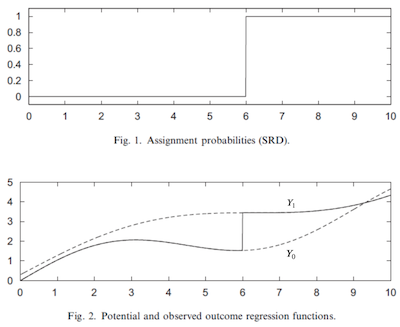

Идея в том, чтобы сравнить исходы чуть выше и чуть ниже порога. Если вероятность воздействия прыгает от 0 до 1, это **резкий RD**. Если она прыгает меньше, это **нечёткий RD**.

### Убивает ли алкоголь?

Минимальный возраст употребления алкоголя в большинстве стран равен 18 годам, а в США 21. Слишком ли осторожны США? Один из способов ответить — посмотреть на [смертность (Карпентер и Добкин, 2009)](https://www.aeaweb.org/articles?id=10.1257/app.1.1.164).

В 21 год доступ к алкоголю легален, и потребление резко растёт. В статье число дней с алкоголем прыгает примерно на 21%. Значит, мы сравниваем людей чуть младше и чуть старше 21 года. Нужно сразу уточнить: воздействие здесь — **легальный доступ к алкоголю**, а не сам алкоголь. Пьют и до 21 года, а доступ не заставляет пить всех.

Каждая строка данных — месячная возрастная группа: средний возраст и смертность на 100 000 человеко-лет по всем причинам (`all`), от ДТП (`mva`), самоубийств (`suicide`) и других причин. Центрируем возраст на пороге и выбрасываем две служебные строки возраста 21.0, в которых смертности нет.

In [56]:
drinking = pd.read_csv(DATA + 'rdd_df_one.csv').dropna(subset=['all'])
drinking['agecell'] -= 21
drinking['threshold'] = (drinking['agecell'] >= 0).astype(int)

print('Групп:', len(drinking))
drinking[['agecell', 'all', 'mva', 'suicide']].head()

Групп: 48


,agecell,all,mva,suicide
0,-1.931507,92.825400,35.829327,11.203714
1,-1.849316,95.100740,35.639256,12.193368
2,-1.767124,92.144295,34.205650,11.715812
3,-1.684930,88.427760,32.278957,11.275010
4,-1.602740,88.704940,32.650967,10.984314


Построим смертность от возраста. Лёгкий скачок на пороге заметен уже здесь.

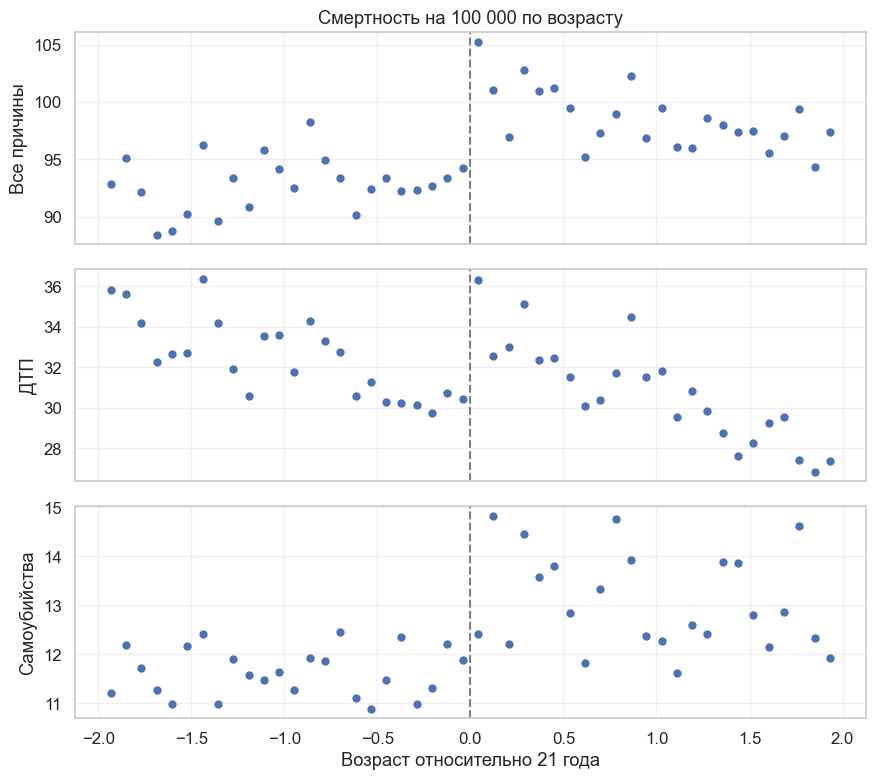

In [57]:
CAUSES = {'all': 'Все причины', 'mva': 'ДТП', 'suicide': 'Самоубийства'}

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (cause, title) in zip(axes, CAUSES.items()):
    ax.scatter(drinking['agecell'], drinking[cause], color=BLUE, s=25)
    ax.axvline(0, color=GRAY, ls='--')
    ax.set_ylabel(title)
axes[0].set_title('Смертность на 100 000 по возрасту')
axes[2].set_xlabel('Возраст относительно 21 года')
plt.tight_layout()

Насколько велик скачок и какова его стандартная ошибка?

### Оценка RDD

Ключевое предположение — **непрерывность потенциальных исходов на пороге**: при подходе к порогу слева и справа потенциальные исходы стремятся к одному значению.

$$
\lim_{r \to c^-} E[Y_{ti}|R_i=r] = \lim_{r \to c^+} E[Y_{ti}|R_i=r], \quad t = 0, 1
$$

Тогда разница наблюдаемых пределов даёт эффект на пороге:

$$
\begin{align}
\lim_{r \to c^+} E[Y_i|R_i=r] - \lim_{r \to c^-} E[Y_i|R_i=r]=&\lim_{r \to c^+} E[Y_{1i}|R_i=r] - \lim_{r \to c^-} E[Y_{0i}|R_i=r] \\
=& E[Y_{1i}|R_i=c] - E[Y_{0i}|R_i=c] \\
=& E[Y_{1i} - Y_{0i}|R_i=c]
\end{align}
$$

Эффект локальный: мы знаем его только на пороге. Вблизи порога RDD похож на локальный эксперимент. В один и тот же момент кому-то чуть больше 21 года, а кому-то чуть меньше, и это зависит от случайной даты рождения. Поэтому RDD считают одним из самых убедительных квази-экспериментов.

Проще всего оценить пределы линейной регрессией со взаимодействием:

$$
y_i = \beta_0 + \beta_1 r_i + \beta_2 \mathcal{1}\{r_i \geq c\} + \beta_3 \mathcal{1}\{r_i \geq c\} r_i
$$

Это то же, что подобрать отдельные прямые слева и справа. Если центрировать $r$ на пороге, $\beta_0$ — предел слева, $\beta_0 + \beta_2$ — предел справа. Поэтому

$$
\lim_{r \to c^+} E[Y_i|R_i=r] - \lim_{r \to c^-} E[Y_i|R_i=r]=\beta_2=E[Y_1 - Y_0|R=c]
$$

In [58]:
def rdd_model(df, outcome, h=None, order=1):
    """Оценивает скачок на пороге; при заданном h использует треугольное ядро."""
    weights = pd.Series(1.0, index=df.index) if h is None else kernel(df['agecell'], c=0, h=h)
    keep = weights > 0
    terms = ' + '.join(f'I(agecell ** {p}) + threshold:I(agecell ** {p})' for p in range(1, order + 1))
    return smf.wls(f'{outcome} ~ threshold + {terms}', df[keep], weights=weights[keep]).fit(cov_type='HC1')


def kernel(R, c, h):
    indicator = (np.abs(R - c) <= h).astype(float)
    return indicator * (1 - np.abs(R - c) / h)


def plot_rdd(ax, outcome, h=None, order=1):
    """Рисует точки и подогнанные линии слева и справа от порога."""
    model = rdd_model(drinking, outcome, h, order)
    limit = 2 if h is None else h
    ax.scatter(drinking['agecell'], drinking[outcome], color=BLUE, s=22, alpha=0.8)
    for side, grid in [(0, np.linspace(-limit, 0, 50)), (1, np.linspace(0, limit, 50))]:
        ax.plot(grid, model.predict(pd.DataFrame({'agecell': grid, 'threshold': side})), color=RED, lw=2.5)
    ax.axvline(0, color=GRAY, ls='--')
    return model


model = rdd_model(drinking, 'all')
print(model.summary().tables[1])

                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    93.6184      0.628    149.165      0.000      92.388      94.848
threshold                     7.6627      1.273      6.017      0.000       5.167      10.159
I(agecell ** 1)               0.8270      0.721      1.147      0.251      -0.586       2.240
threshold:I(agecell ** 1)    -3.6034      1.124     -3.207      0.001      -5.806      -1.401


Скачок равен 7.66 смерти на 100 000. Стандартная ошибка здесь устойчива к гетероскедастичности. То же для других причин.

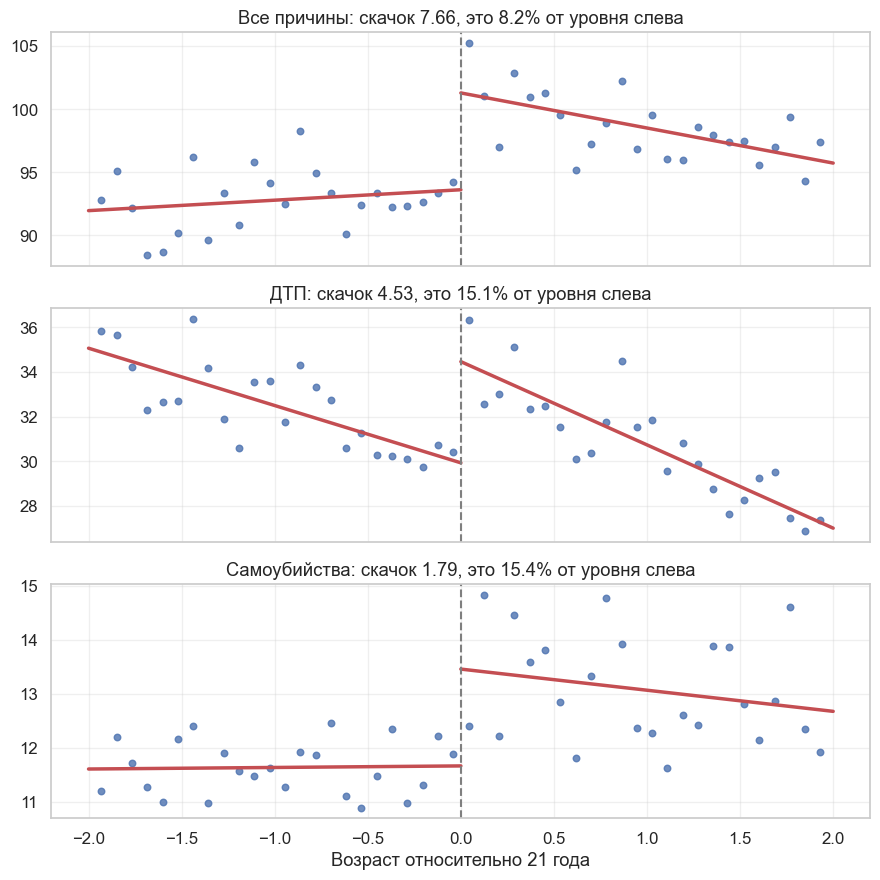

In [59]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, (cause, title) in zip(axes, CAUSES.items()):
    m = plot_rdd(ax, cause)
    jump_pct = 100 * m.params['threshold'] / m.params['Intercept']
    ax.set_title(f"{title}: скачок {m.params['threshold']:.2f}, это {jump_pct:.1f}% от уровня слева")
axes[2].set_xlabel('Возраст относительно 21 года')
plt.tight_layout()

Смертность от всех причин растёт на 8.2%, а от ДТП и самоубийств примерно на 15%. Для сравнения: в статье Карпентера и Добкина это 9% от всех причин, 14% от ДТП и 15% от самоубийств.

Можно ли сразу сделать вывод о политике? Осторожно. Скачок относится к 21 году и не говорит, что будет при переносе порога на 18 лет. Кроме того, смертность — не единственный критерий. RDD показывает только то, что доступ к алкоголю в 21 год увеличивает смертность.

### Ядерное взвешивание

RDD зависит от того, как линия ведёт себя у порога. Если модель подгоняет далёкие точки, она может плохо описать пределы. Поэтому точкам у порога дают больший вес, чаще всего с помощью **треугольного ядра**:

$$
K(R, c, h) = \mathcal{1}\{|R-c| \leq h\} \cdot \bigg(1-\frac{|R-c|}{h}\bigg)
$$

Первая часть отбирает точки в окне шириной $h$, вторая снижает вес с расстоянием. При $h=1$ используются только люди от 20 до 22 лет.

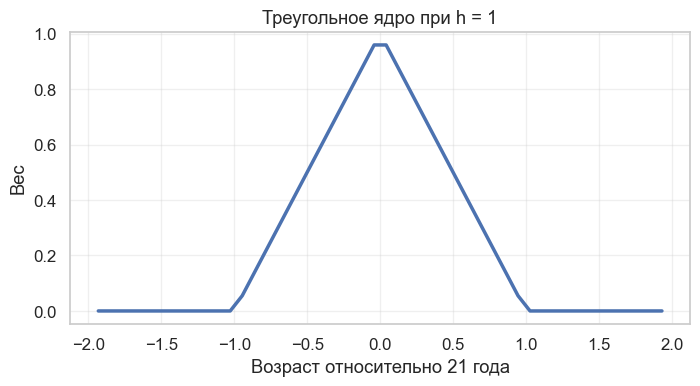

In [60]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(drinking['agecell'], kernel(drinking['agecell'], c=0, h=1), color=BLUE, lw=2.5)
ax.set_xlabel('Возраст относительно 21 года')
ax.set_ylabel('Вес')
ax.set_title('Треугольное ядро при h = 1');

С такими весами оценка для всех причин вырастает с 7.66 до 9.70.

                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    93.2002      0.661    140.920      0.000      91.904      94.497
threshold                     9.7004      1.932      5.022      0.000       5.915      13.486
I(agecell ** 1)               0.4109      2.041      0.201      0.840      -3.590       4.412
threshold:I(agecell ** 1)    -7.1759      4.022     -1.784      0.074     -15.058       0.706


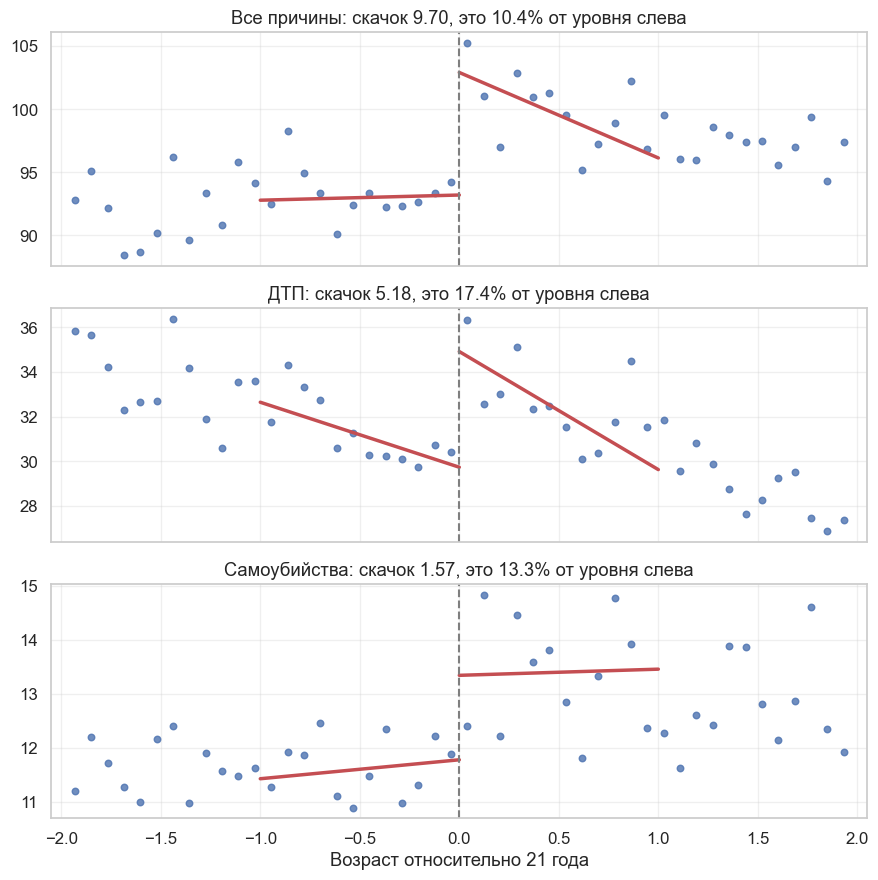

In [61]:
kernel_model = rdd_model(drinking, 'all', h=1)
print(kernel_model.summary().tables[1])

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, (cause, title) in zip(axes, CAUSES.items()):
    m = plot_rdd(ax, cause, h=1)
    ax.set_xlim(-2.05, 2.05)
    jump_pct = 100 * m.params['threshold'] / m.params['Intercept']
    ax.set_title(f"{title}: скачок {m.params['threshold']:.2f}, это {jump_pct:.1f}% от уровня слева")
axes[2].set_xlabel('Возраст относительно 21 года')
plt.tight_layout()

Оценки для всех причин и ДТП выросли, для самоубийств немного снизились. Но выбор $h$ был произвольным. Подвигайте ширину окна и степень многочлена. На гифке то же окно сужается автоматически: она работает и без запуска ноутбука.

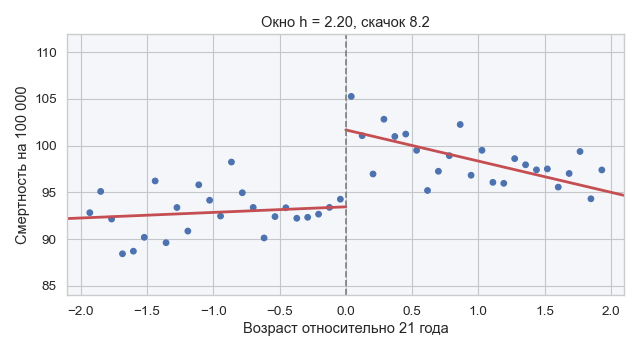

In [62]:
def rdd_demo(h=1.0, order=1):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    m = plot_rdd(ax, 'all', h, order)
    ax.set_xlim(-2.05, 2.05)
    low, high = m.conf_int().loc['threshold']
    ax.set_title(f"Скачок {m.params['threshold']:.2f}, 95% ДИ [{low:.2f}, {high:.2f}], групп: {int(m.nobs)}")
    ax.set_xlabel('Возраст относительно 21 года')
    ax.set_ylabel('Смертность')
    plt.show()


interact(rdd_demo,
         h=FloatSlider(value=1, min=0.4, max=3, step=0.1, description='Окно h'),
         order=IntSlider(value=1, min=1, max=3, description='Степень'));

Статичная версия: оценка для разных окон и степеней. Такой график стоит показывать в любом исследовании с RDD.

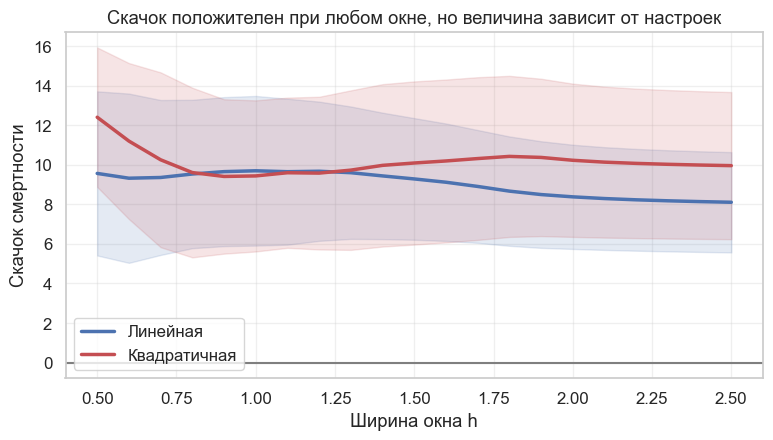

In [63]:
bandwidths = np.arange(0.5, 2.51, 0.1)

fig, ax = plt.subplots(figsize=(9, 4.5))
for order, color, label in [(1, BLUE, 'Линейная'), (2, RED, 'Квадратичная')]:
    models = [rdd_model(drinking, 'all', h, order) for h in bandwidths]
    jump = np.array([m.params['threshold'] for m in models])
    se = np.array([m.bse['threshold'] for m in models])
    ax.plot(bandwidths, jump, color=color, lw=2.5, label=label)
    ax.fill_between(bandwidths, jump - 1.96 * se, jump + 1.96 * se, color=color, alpha=0.15)
ax.axhline(0, color=GRAY)
ax.set_xlabel('Ширина окна h')
ax.set_ylabel('Скачок смертности')
ax.set_title('Скачок положителен при любом окне, но величина зависит от настроек')
ax.legend();

Линейная модель даёт от 8.1 до 9.7, квадратичная от 9.4 до 12.4. Интервалы ни при каком окне не включают ноль. Значит, вывод о существовании скачка устойчив, а его величина известна с точностью примерно от 8 до 12.

Проверим устойчивость ещё четырьмя способами.

* **Готовая реализация.** Пакет `rdrobust` сам выбирает окно и строит интервалы с поправкой на смещение.
* **Причины смерти как плацебо.** Болезни (`internal`) не должны резко реагировать на доступ к алкоголю, а отравления алкоголем (`alcohol`) должны.
* **Ложные пороги.** В других возрастах скачка быть не должно.
* **Выброс групп у порога.** Первая группа после порога включает сам 21-й день рождения. Если весь эффект держится на ней, это разовое празднование, а не следствие постоянного доступа.

rdrobust: скачок 9.59, окно 0.49, робастный 95% ДИ [1.08, 18.30]


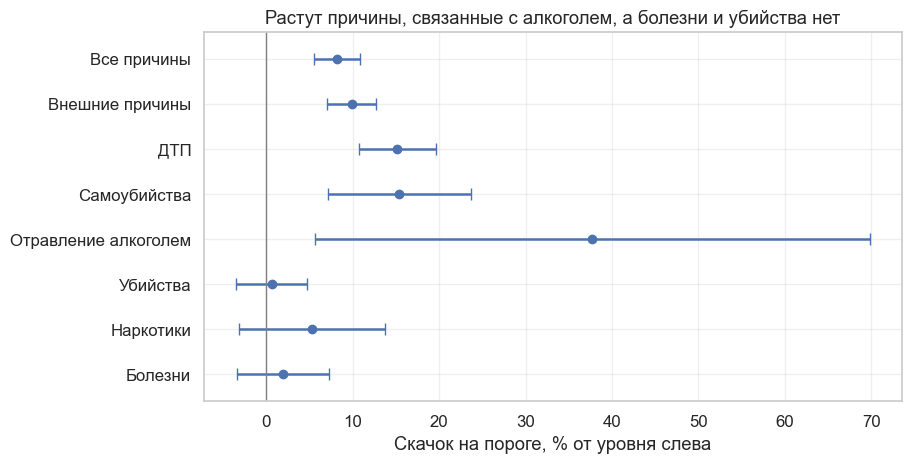

In [64]:
robust = rdrobust(drinking['all'].to_numpy(), drinking['agecell'].to_numpy())
print(f"rdrobust: скачок {robust.coef.iloc[0, 0]:.2f}, окно {robust.bws.iloc[0, 0]:.2f}, робастный 95% ДИ [{robust.ci.iloc[2, 0]:.2f}, {robust.ci.iloc[2, 1]:.2f}]")

causes = {'all': 'Все причины', 'external': 'Внешние причины', 'mva': 'ДТП', 'suicide': 'Самоубийства', 'alcohol': 'Отравление алкоголем',
          'homicide': 'Убийства', 'drugs': 'Наркотики', 'internal': 'Болезни'}


def relative_row(cause, title):
    m = rdd_model(drinking, cause)
    base = m.params['Intercept']
    low, high = m.conf_int().loc['threshold']
    return {'Модель': title, 'Оценка': 100 * m.params['threshold'] / base, 'ДИ 2.5%': 100 * low / base, 'ДИ 97.5%': 100 * high / base}


fig, ax = plt.subplots(figsize=(9, 4.8))
plot_forest(ax, pd.DataFrame([relative_row(c, t) for c, t in causes.items()]), 'Скачок на пороге, % от уровня слева')
ax.set_title('Растут причины, связанные с алкоголем, а болезни и убийства нет');

In [65]:
def fake_cutoff(cut):
    """Ищет скачок на ложном пороге, используя данные только с одной стороны от настоящего."""
    side = drinking[drinking['agecell'] < 0] if cut < 0 else drinking[drinking['agecell'] >= 0]
    side = side.assign(agecell=side['agecell'] - cut, threshold=(side['agecell'] >= cut).astype(int))
    m = rdd_model(side, 'all')
    return {'Порог': 21 + cut, 'Скачок': m.params['threshold'], 'SE': m.bse['threshold'], 'p-value': m.pvalues['threshold']}


display(pd.DataFrame([fake_cutoff(c) for c in [-1.5, -1, -0.5, 0.5, 1, 1.5]]).round(3))

donut = drinking[drinking['agecell'].abs() > 0.05]
for name, part in [('Все группы', drinking), ('Без групп вплотную к порогу', donut)]:
    m = rdd_model(part, 'all', h=2)
    print(f"{name}: скачок {m.params['threshold']:.2f}, SE {m.bse['threshold']:.2f}")

,Порог,Скачок,SE,p-value
0,19.5,5.250,1.815,0.004
1,20.0,0.920,2.054,0.654
2,20.5,-1.469,1.427,0.303
3,21.5,-1.593,1.617,0.325
4,22.0,0.463,1.891,0.807
5,22.5,0.598,1.180,0.612


Все группы: скачок 8.38, SE 1.34
Без групп вплотную к порогу: скачок 7.56, SE 1.21


* `rdrobust` выбрал окно 0.49 года и дал скачок 9.6 с робастным интервалом [1.1, 18.3]. Интервал намного шире нашего: в таком окне по шесть групп с каждой стороны.
* Скачок заметен в ДТП, самоубийствах и отравлениях алкоголем: 15%, 15% и 38%. Болезни (1.9%), убийства (0.6%) и наркотики (5.2%) значимо не меняются. Это хорошо согласуется с причинной историей: отравления по определению связаны с алкоголем, а болезни от него сразу не появляются.
* На пяти из шести ложных порогов скачка нет. Исключение — 19.5 года: скачок 5.25, p = 0.004. Там слева меньше полугода данных, но это всё равно предупреждение: такие шумовые скачки в этих данных бывают. Настоящий скачок при этом больше, и его поддерживают другие проверки.
* После выброса групп вплотную к порогу оценка падает с 8.4 до 7.6, но остаётся большой и значимой. Значит, дело не только в дне рождения.

### Эффект овечьей шкуры и нечёткий RDD

Как образование влияет на заработок? Есть две основные точки зрения. Первая — **человеческий капитал**: образование делает вас продуктивнее. Вторая — **сигнальная**: образование лишь показывает рынку, какими способными вы были всегда. Тогда важен сам диплом. Это называют **эффектом овечьей шкуры**: раньше дипломы печатали на пергаменте из неё.

Чтобы проверить гипотезу, [Кларк и Марторелл](https://faculty.smu.edu/millimet/classes/eco7321/papers/clark%20martorell%202014.pdf) сравнили людей, которые едва сдали и едва не сдали выпускной экзамен в школе.

Чтобы получить аттестат в Техасе, нужно сдать экзамен. Попыток несколько, начиная с 10-го класса, а в конце 12-го остаётся последняя. Едва сдавшие и едва не сдавшие обладают почти одинаковым человеческим капиталом, но разными дипломами.

Данные снова сгруппированы по переменной назначения. `minscore` — балл относительно проходного, `avgearnings` — средний годовой заработок, `receivehsd` — доля получивших аттестат, `n` — размер группы. Например, из 12 человек с баллом -30 аттестат получили 5.

Обратите внимание на порог: **балл 0 означает, что экзамен сдан**. Доля аттестатов прыгает при переходе от -1 к 0: с 47% до 92%. Поэтому переменная порога должна быть равна единице при `minscore >= 0`.

Скачок не от нуля до единицы: часть не сдавших всё равно получает аттестат, а часть сдавших нет. Значит, разрыв **нечёткий**.

   avgearnings  minscore  receivehsd   n
0    11845.086     -30.0    0.416667  12
1     9205.679     -29.0    0.387097  31
2     8407.745     -28.0    0.318182  44
3    11114.087     -27.0    0.377778  45
4    10814.624     -26.0    0.306667  75
 minscore  receivehsd
     -3.0       0.441
     -2.0       0.454
     -1.0       0.465
      0.0       0.916
      1.0       0.906
      2.0       0.928


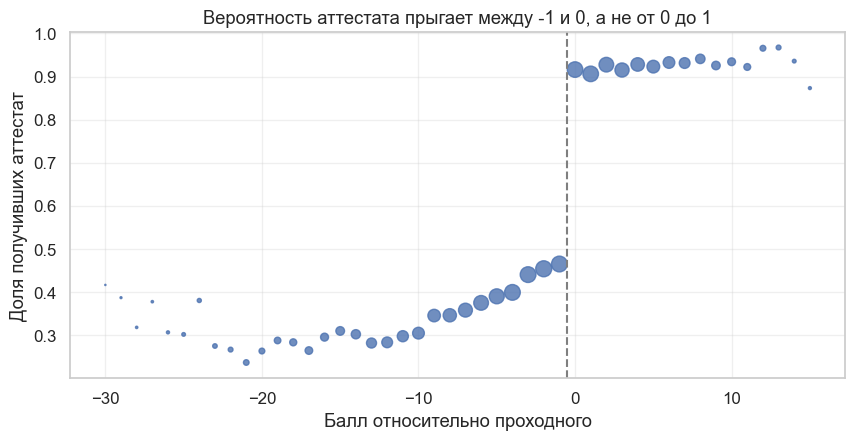

In [66]:
sheepskin = pd.read_csv(DATA + 'rdd_df_two.csv')[['avgearnings', 'minscore', 'receivehsd', 'n']]
print(sheepskin.head())
print(sheepskin[sheepskin['minscore'].between(-3, 2)][['minscore', 'receivehsd']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(sheepskin['minscore'], sheepskin['receivehsd'], s=sheepskin['n'] / 15, color=BLUE, alpha=0.8)
ax.axvline(-0.5, color=GRAY, ls='--')
ax.set_xlabel('Балл относительно проходного')
ax.set_ylabel('Доля получивших аттестат')
ax.set_title('Вероятность аттестата прыгает между -1 и 0, а не от 0 до 1');

Нечёткий RDD — это вид несоблюдения. Здесь есть потенциальное воздействие: $T_1$ получил бы человек выше порога, а $T_0$ ниже. Иначе говоря, **порог — это инструментальная переменная**. Как и в IV, наивный скачок смещён к нулю.

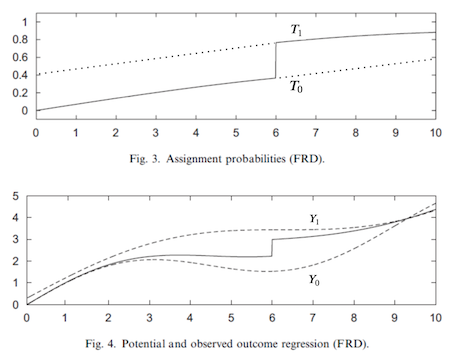

Выше порога воздействие получают не все, поэтому наблюдаемый исход ниже $Y_1$. Ниже порога получают некоторые, поэтому он выше $Y_0$. Скачок выглядит меньше настоящего эффекта.

Предположим гладкость потенциального воздействия на пороге и монотонность: $T_{1i} \geq T_{0i}$ для всех $i$, то есть сдача экзамена не уменьшает шанс получить диплом. Тогда получаем оценку Вальда для LATE:

$$
\dfrac{\lim_{r \to c^+} E[Y_i|R_i=r] - \lim_{r \to c^-} E[Y_i|R_i=r]}{\lim_{r \to c^+} E[T_i|R_i=r] - \lim_{r \to c^-} E[T_i|R_i=r]} = E[Y_{1i} - Y_{0i} | T_{1i} > T_{0i}, R_i=c]
$$

Оценка локальна в двух смыслах: она относится только к порогу (локальность RD) и только к соблюдающим (локальность IV).

Числитель считается так же, как в резком RD, а в знаменателе вместо исхода стоит воздействие. Но сначала проверим, можно ли доверять дизайну.

### Тест МакКрари

Дизайн ломается, если люди могут управлять своим положением относительно порога. Например, если едва не сдавшие находят способ добавить балл или если семьи занижают доход, чтобы получить пособие. Тогда у порога появляется скопление, и выше него окажутся не случайные люди.

Тест МакКрари (2008) проверяет, есть ли разрыв в плотности переменной назначения. Его идея проста: сгладить гистограмму слева и справа и сравнить логарифмы плотности на пороге. В наших данных плотность задаёт столбец `n`. Сделаем упрощённый вариант на группах: это та же регрессия на пороге, но для логарифма числа людей. На втором графике показано, как выглядело бы искусственное скопление.

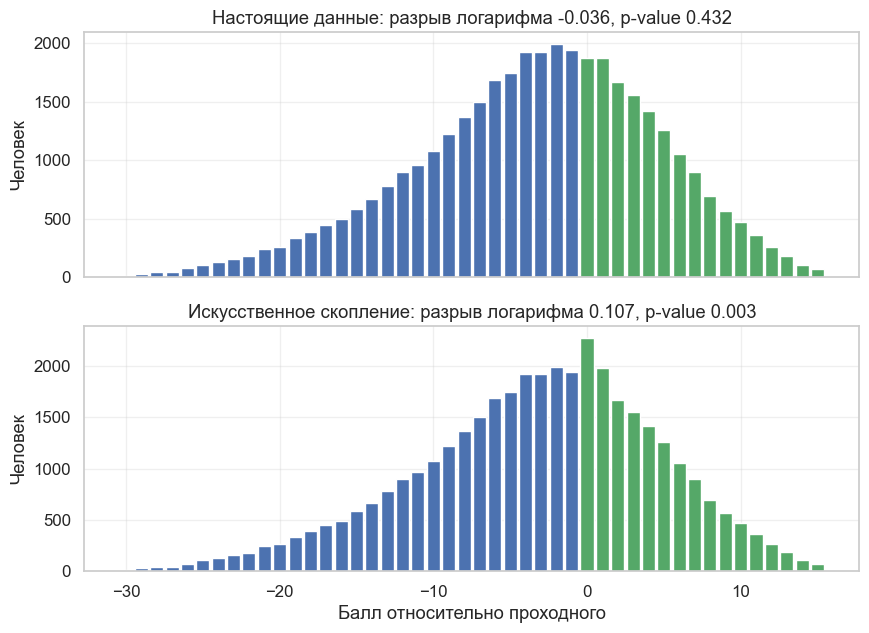

h = 6: p-value настоящих данных 0.432, со скоплением 0.003
h = 10: p-value настоящих данных 0.485, со скоплением 0.258
h = 16: p-value настоящих данных 0.930, со скоплением 0.366


In [67]:
def density_jump(cells, h=6):
    """Оценивает разрыв логарифма числа людей на пороге: упрощённая версия теста МакКрари."""
    cells = cells.assign(log_n=np.log(cells['n']), threshold=(cells['minscore'] >= 0).astype(int))
    weights = kernel(cells['minscore'], c=0, h=h)
    keep = weights > 0
    return smf.wls('log_n ~ minscore * threshold', cells[keep], weights=weights[keep]).fit(cov_type='HC1')


manipulated = sheepskin.copy()
manipulated.loc[manipulated['minscore'] == 0, 'n'] += 400
manipulated.loc[manipulated['minscore'] == 1, 'n'] += 100

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, cells, title in [(axes[0], sheepskin, 'Настоящие данные'), (axes[1], manipulated, 'Искусственное скопление')]:
    jump = density_jump(cells)
    ax.bar(cells['minscore'], cells['n'], color=np.where(cells['minscore'] >= 0, GREEN, BLUE), width=0.85)
    ax.set_title(f"{title}: разрыв логарифма {jump.params['threshold']:.3f}, p-value {jump.pvalues['threshold']:.3f}")
    ax.set_ylabel('Человек')
axes[1].set_xlabel('Балл относительно проходного')
plt.show()

for h in [6, 10, 16]:
    real, fake = density_jump(sheepskin, h), density_jump(manipulated, h)
    print(f"h = {h}: p-value настоящих данных {real.pvalues['threshold']:.3f}, со скоплением {fake.pvalues['threshold']:.3f}")

При узком окне $h = 6$ в настоящих данных разрыва нет, $p = 0.43$, а искусственное скопление тест находит, $p = 0.003$. Но при $h = 16$ то же самое скопление уже не видно: $p = 0.37$. Широкое окно размазывает локальный всплеск, поэтому результат теста, как и оценку RDD, надо смотреть при разных окнах. Отсутствие разрыва не доказывает отсутствие манипуляции, но у нас нет признаков, что студенты управляли положением относительно порога.

Перейдём к оценке эффекта. Используем ядро с шириной окна 15 и умножим его на размер группы, чтобы получить вес.

In [68]:
sheepskin_rdd = sheepskin.assign(threshold=(sheepskin['minscore'] >= 0).astype(int))
sheepskin_rdd['weight'] = kernel(sheepskin_rdd['minscore'], c=0, h=15) * sheepskin_rdd['n']
window = sheepskin_rdd[sheepskin_rdd['weight'] > 0]

reduced = smf.wls('avgearnings ~ minscore * threshold', window, weights=window['weight']).fit(cov_type='HC1')
first = smf.wls('receivehsd ~ minscore * threshold', window, weights=window['weight']).fit(cov_type='HC1')

print(reduced.summary().tables[1])
print('Первая стадия:', round(first.params['threshold'], 3), 'SE:', round(first.bse['threshold'], 3))
print('Оценка Вальда:', round(reduced.params['threshold'] / first.params['threshold'], 1))

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           1.395e+04    170.052     82.030      0.000    1.36e+04    1.43e+04
minscore             175.5723     25.537      6.875      0.000     125.520     225.625
threshold             13.9664    215.721      0.065      0.948    -408.839     436.772
minscore:threshold    11.6318     35.772      0.325      0.745     -58.480      81.744
Первая стадия: 0.432 SE: 0.006
Оценка Вальда: 32.4


Скачок заработка на пороге равен 14 долларам и статистически не отличается от нуля. Первая стадия равна 0.43, поэтому оценка Вальда около 32 долларов. На графике линия проходит через порог почти без разрыва. Люди с большими баллами зарабатывают больше, но скачка на дипломе нет.

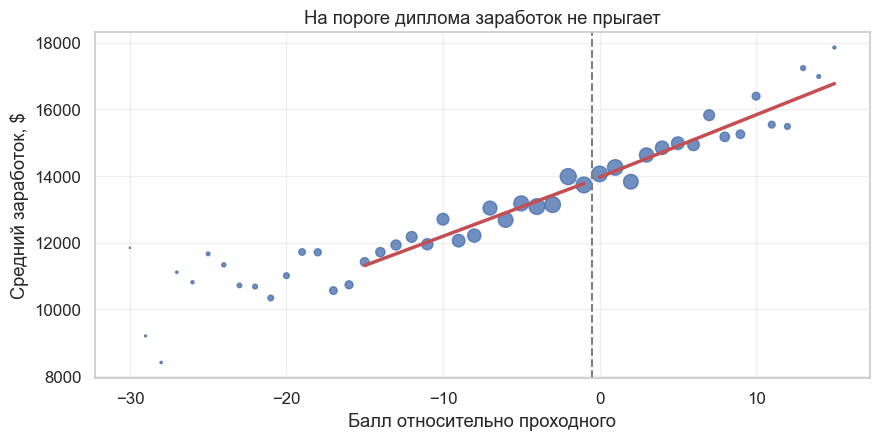

In [69]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(sheepskin['minscore'], sheepskin['avgearnings'], s=sheepskin['n'] / 15, color=BLUE, alpha=0.8)
for side, grid in [(0, np.linspace(-15, -1, 30)), (1, np.linspace(0, 15, 30))]:
    ax.plot(grid, reduced.predict(pd.DataFrame({'minscore': grid, 'threshold': side})), color=RED, lw=2.5)
ax.axvline(-0.5, color=GRAY, ls='--')
ax.set_xlabel('Балл относительно проходного')
ax.set_ylabel('Средний заработок, $')
ax.set_title('На пороге диплома заработок не прыгает');

Нужно оценить неопределённость оценки Вальда. Нечёткий RDD — это IV, поэтому его можно посчитать тем же `IV2SLS` с весами: инструмент — порог, воздействие — аттестат. Сравним три варианта: 2SLS, бутстреп по группам и `rdrobust`.

IV2SLS: 32.4, SE 464.0, 95% ДИ [-877, 942]


Бутстреп: SE 577.8, 95% ДИ [-1195, 1135]
rdrobust: -212.4, окно 5.5, робастный 95% ДИ [-2487, 1991]


Отношение границы ДИ к заработку у порога: 6.8 %


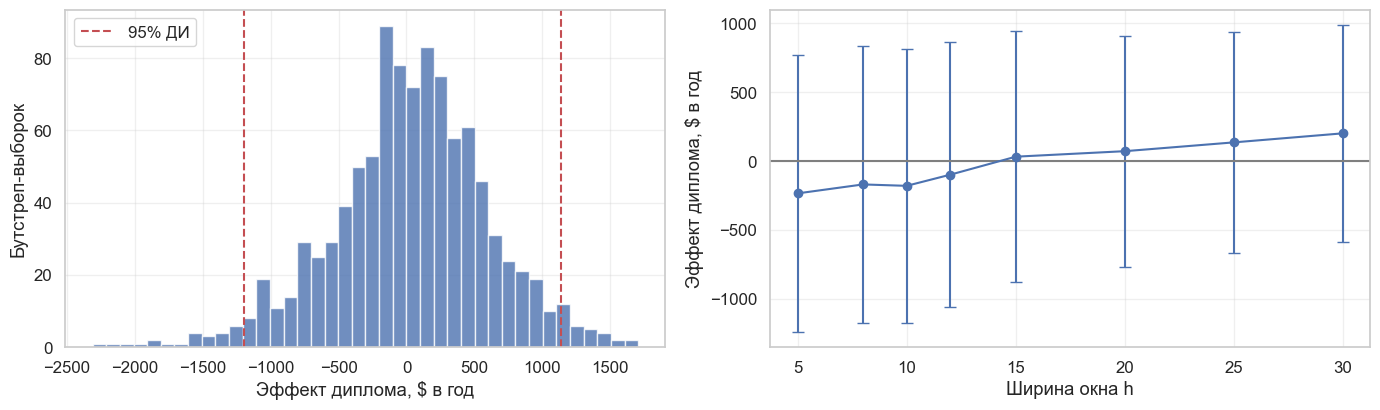

In [70]:
def wald_rdd(cells):
    weights = kernel(cells['minscore'], c=0, h=15) * cells['n']
    keep = weights > 0
    numerator = smf.wls('avgearnings ~ minscore * threshold', cells[keep], weights=weights[keep]).fit()
    denominator = smf.wls('receivehsd ~ minscore * threshold', cells[keep], weights=weights[keep]).fit()
    return numerator.params['threshold'] / denominator.params['threshold']


formula = 'avgearnings ~ 1 + minscore + minscore:threshold + [receivehsd ~ threshold]'
fuzzy_iv = IV2SLS.from_formula(formula, window, weights=window['weight']).fit()
low, high = fuzzy_iv.conf_int().loc['receivehsd']
print(f"IV2SLS: {fuzzy_iv.params['receivehsd']:.1f}, SE {fuzzy_iv.std_errors['receivehsd']:.1f}, 95% ДИ [{low:.0f}, {high:.0f}]")

boot_rng = np.random.default_rng(45)
n_boot = 1000
wald_boot = np.array([wald_rdd(sheepskin_rdd.sample(frac=1, replace=True, random_state=boot_rng)) for _ in range(n_boot)])
boot_low, boot_high = np.percentile(wald_boot, [2.5, 97.5])
print(f'Бутстреп: SE {wald_boot.std():.1f}, 95% ДИ [{boot_low:.0f}, {boot_high:.0f}]')

robust = rdrobust(sheepskin['avgearnings'].to_numpy(), sheepskin['minscore'].to_numpy(),
                  fuzzy=sheepskin['receivehsd'].to_numpy(), weights=sheepskin['n'].to_numpy(), c=0)
print(f"rdrobust: {robust.coef.iloc[0, 0]:.1f}, окно {robust.bws.iloc[0, 0]:.1f}, робастный 95% ДИ [{robust.ci.iloc[2, 0]:.0f}, {robust.ci.iloc[2, 1]:.0f}]")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].hist(wald_boot, bins=40, color=BLUE, alpha=0.8)
axes[0].axvline(boot_low, color=RED, ls='--', label='95% ДИ')
axes[0].axvline(boot_high, color=RED, ls='--')
axes[0].set_xlabel('Эффект диплома, $ в год')
axes[0].set_ylabel('Бутстреп-выборок')
axes[0].legend()

bandwidths = [5, 8, 10, 12, 15, 20, 25, 30]
rows = []
for h in bandwidths:
    part = sheepskin_rdd.assign(weight=kernel(sheepskin_rdd['minscore'], c=0, h=h) * sheepskin_rdd['n']).query('weight > 0')
    fit = IV2SLS.from_formula(formula, part, weights=part['weight']).fit()
    rows.append((fit.params['receivehsd'], fit.std_errors['receivehsd']))
estimate, se = map(np.array, zip(*rows))
axes[1].errorbar(bandwidths, estimate, yerr=1.96 * se, fmt='o-', color=BLUE, capsize=4)
axes[1].axhline(0, color=GRAY)
axes[1].set_xlabel('Ширина окна h')
axes[1].set_ylabel('Эффект диплома, $ в год')
plt.tight_layout()
print('Отношение границы ДИ к заработку у порога:', round(100 * high / reduced.params['Intercept'], 1), '%')

`IV2SLS` с весами даёт ту же оценку 32 доллара со стандартной ошибкой 464 и интервалом [-877, 942]. Значит, нечёткий RDD можно посчитать готовыми средствами Python. Бутстреп по группам даёт более широкий интервал [-1195, 1135], а `rdrobust` с узким окном 5.5 — оценку -212 и интервал [-2487, 1991]. При разных окнах оценка меняется от -234 до 202 и всегда незначима.

Отсутствие значимости не доказывает отсутствие эффекта. Но заработок у порога около 13 950 долларов в год, поэтому интервал `IV2SLS` исключает эффекты больше примерно 7% заработка, а бутстреп — больше 8%. При узком окне неопределённость примерно вдвое выше. Это аргумент против сильной версии сигнальной гипотезы. Однако отсюда не следует, что образование повышает доход за счёт производительности: эта оценка относится к людям у порога последнего экзамена и только к диплому при уже пройденных годах школы. Сами годы обучения RDD не оценивает. Авторы статьи тоже находят мало свидетельств сигнального эффекта: в рабочей версии они отвергают эффект диплома больше 8% для каждого из двух штатов.

## Заключение

| Метод | Что оценивает | Ключевое предположение | Что можно проверить |
| :--- | :--- | :--- | :--- |
| Регрессия | Эффект при фиксированных контролях | Все конфаундеры измерены, плохих контролей нет | Устойчивость к набору контролей |
| IV | LATE для соблюдающих | Независимость, исключение, монотонность | Силу первой стадии |
| RDD | Эффект на пороге | Непрерывность потенциальных исходов | Плотность, ложные пороги, плацебо-исходы, окно |
| Нечёткий RDD | LATE на пороге | То же, плюс монотонность | То же, плюс первую стадию |

Главное из лекции:

* разница средних равна ATT плюс смещение, а рандомизация его убирает;
* регрессия убирает смещение только от измеренных конфаундеров, а знак OVB равен произведению знаков двух стрелок;
* предикторы исхода, измеренные до воздействия, сужают интервалы, но выбирать их нужно заранее;
* нельзя контролировать ничего, на что могло повлиять воздействие: это ломает оценку даже в рандомизированном эксперименте;
* инструмент должен быть не только сильным, но и не связанным с конфаундерами, причём последнее на данных не проверить;
* при несоблюдении есть три разные величины: ITT, эффект по факту получения и LATE. Первая и третья корректны, но отвечают на разные вопросы;
* результат RDD всегда нужно показывать при разных окнах, а в нечётком варианте проверять, где именно проходит порог.